# 09 - Obstacle Avoidance and AV

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Beyond Pure Pursuit: Reactive Obstacle Avoidance

`back_end_resources/systems_primer/04b_motion_control_and_trajectories`'s Pure Pursuit is a working path-follower, but it follows a path that was generated once, in advance. It has no way to notice that a robot rolled into the middle of that path a moment ago. `08-decision-making.ipynb`'s collision check handles this for one specific candidate action against one predicted trajectory. But a planner often needs a broader picture: everything nearby that's currently occupied, static, or moving.

An **occupancy grid** is the standard way to build that picture. Discretize the field into small cells, and mark each cell occupied or free based on what perception currently reports. Every tracked robot from `05`'s SORT pipeline becomes a filled-in region (its position, inflated by its footprint and a safety margin), and everything else is free space. This turns a list of detections into something a path-checker (or a full replanner in the next section) can query directly, and ask "is this candidate path passing through anything occupied?"

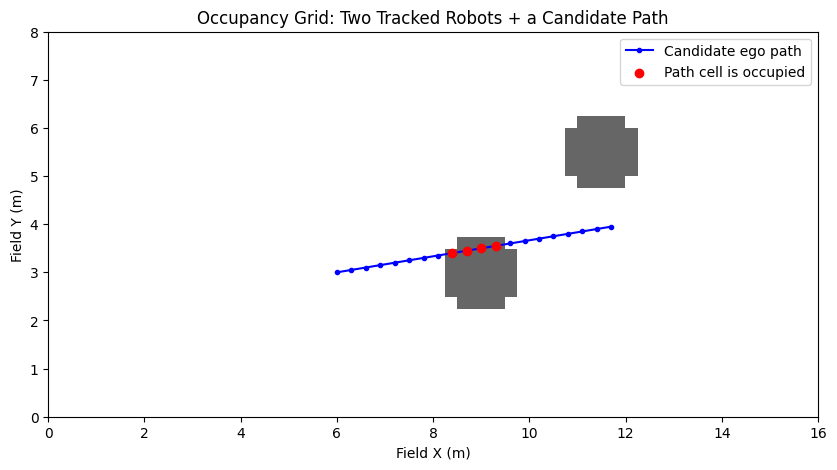

Path cells occupied: 4 / 20


In [2]:
FIELD_LENGTH, FIELD_WIDTH = 16.0, 8.0   # meters; a simplified stand-in for our field
CELL_SIZE = 0.25
grid_w = int(FIELD_LENGTH / CELL_SIZE)
grid_h = int(FIELD_WIDTH / CELL_SIZE)

# two tracked robots (the kind 05's SORT pipeline reports) as field-relative poses
tracked_robots = [
    {"position": np.array([9.0, 3.0]), "footprint_radius": 0.45},
    {"position": np.array([11.5, 5.5]), "footprint_radius": 0.45},
]
SAFETY_MARGIN = 0.3

grid = np.zeros((grid_h, grid_w))
cell_centers_x = (np.arange(grid_w) + 0.5) * CELL_SIZE
cell_centers_y = (np.arange(grid_h) + 0.5) * CELL_SIZE
xx, yy = np.meshgrid(cell_centers_x, cell_centers_y)

for robot in tracked_robots:
    dist = np.sqrt((xx - robot["position"][0]) ** 2 + (yy - robot["position"][1]) ** 2)
    grid[dist <= robot["footprint_radius"] + SAFETY_MARGIN] = 1

# a candidate ego path (e.g. the kind of straight-line plan 08's collision-check tested)
ego_path = np.array([[6.0 + 0.3 * s, 3.0 + 0.05 * s] for s in range(20)])
path_cols = np.clip((ego_path[:, 0] / CELL_SIZE).astype(int), 0, grid_w - 1)
path_rows = np.clip((ego_path[:, 1] / CELL_SIZE).astype(int), 0, grid_h - 1)
blocked = grid[path_rows, path_cols]

plt.figure(figsize=(10, 5))
plt.imshow(grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
plt.plot(ego_path[:, 0], ego_path[:, 1], "o-", color="blue", markersize=3, label="Candidate ego path")
plt.scatter(ego_path[blocked == 1, 0], ego_path[blocked == 1, 1], color="red", zorder=5, label="Path cell is occupied")
plt.xlabel("Field X (m)")
plt.ylabel("Field Y (m)")
plt.title("Occupancy Grid: Two Tracked Robots + a Candidate Path")
plt.legend()
plt.show()

print(f"Path cells occupied: {int(blocked.sum())} / {len(blocked)}")

## The Idea of Replanning

The occupancy grid above tells you a candidate path is blocked, but it doesn't tell you what to do instead. That's **replanning**: searching for a new path through the free cells. Two families of algorithm dominate this problem. 

### Search-Based Planning 

We treat the occupancy grid as a graph, where each free cell connects to its neighbors, and we search for the lowest-cost path from start to goal. This is how GPS route-finders find your fastest route! 

A\* is one of the more famous algorithms for searches, because it is exact and finds the shortest free path. However, it scales poorly as we add in dimensions like position, heading, and velocity. 

### Sampling-Based Planning

Instead of an exhaustive grid search, we randomly sample points in the free space and grow a tree of reachable paths outward from the start until it reaches the goal. One such algorithm, Rapidly-Exploring Random Tree (RRT), doesn't guarantee the shortest path, but it scales far better than A\*.

We'll build both. A\* comes first, because it consumes exactly the occupancy grid already built above and is the right tool for the 2D version of this problem. RRT comes right after it, applied to the harder versions.

## A Minimal Grid-Based A*

A* treats the occupancy grid from the last section as a graph. Each free cell is a node, connected to its (up to 8) neighboring free cells. Starting from the robot's current cell, it repeatedly expands whichever reachable cell looks most promising based on the cost already spent getting there, plus a heuristic estimate of the remaining distance to the goal, until it reaches the goal cell. 

A\* gives us unique guarantees. One is that if a path exists, it will find the shortest one, provided the heuristic used doesn't overestimate the true remaining distance (you can use a basic Euclidean distance to guarantee that). 

Two is that if no path exists, A\* will tell us instead of running forever or returning a bad guess. 

A* found a path (23 cells)


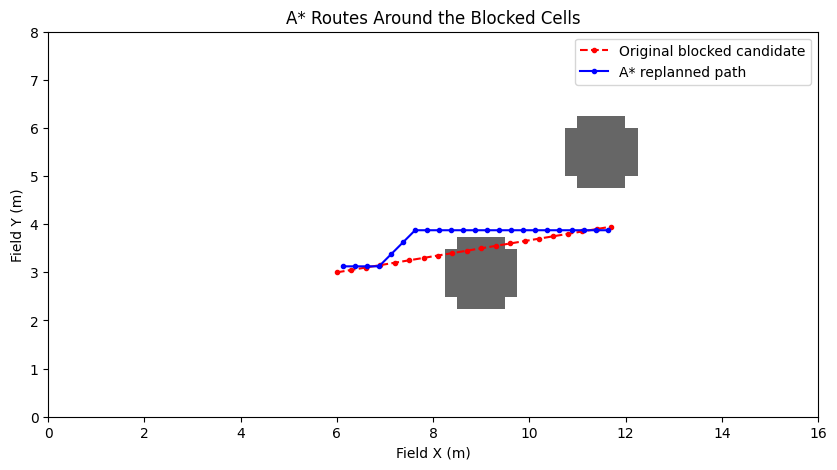

In [3]:
import heapq

def a_star(grid, start_cell, goal_cell):
    """ start_cell/goal_cell are (row, col) grid indices. Returns the path as a list of
    (row, col) from start to goal, or None if no path exists. """
    h, w = grid.shape

    def heuristic(a, b):
        return np.hypot(a[0] - b[0], a[1] - b[1])

    def neighbors(cell):
        r, c = cell
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and grid[nr, nc] == 0:
                yield (nr, nc), np.hypot(dr, dc)

    open_set = [(heuristic(start_cell, goal_cell), 0.0, start_cell)]
    came_from = {}
    cost_so_far = {start_cell: 0.0}

    while open_set:
        _, g, current = heapq.heappop(open_set)
        if current == goal_cell:
            path = [current]
            while path[-1] in came_from:
                path.append(came_from[path[-1]])
            return path[::-1]
        for neighbor, step_cost in neighbors(current):
            new_cost = g + step_cost
            if neighbor not in cost_so_far or new_cost < cost_so_far[neighbor]:
                cost_so_far[neighbor] = new_cost
                priority = new_cost + heuristic(neighbor, goal_cell)
                heapq.heappush(open_set, (priority, new_cost, neighbor))
                came_from[neighbor] = current

    return None  # no path exists

# reuse the exact occupancy grid and blocked candidate path from the section above
start_field, goal_field = ego_path[0], ego_path[-1]
start_cell = (int(start_field[1] / CELL_SIZE), int(start_field[0] / CELL_SIZE))
goal_cell = (int(goal_field[1] / CELL_SIZE), int(goal_field[0] / CELL_SIZE))

found_path = a_star(grid, start_cell, goal_cell)
print(f"A* {'found a' if found_path else 'found no'} path"
      + (f" ({len(found_path)} cells)" if found_path else ""))

plt.figure(figsize=(10, 5))
plt.imshow(grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
plt.plot(ego_path[:, 0], ego_path[:, 1], "o--", color="red", markersize=3, label="Original blocked candidate")
if found_path:
    found_path_field = np.array([[(c + 0.5) * CELL_SIZE, (r + 0.5) * CELL_SIZE] for r, c in found_path])
    plt.plot(found_path_field[:, 0], found_path_field[:, 1], "o-", color="blue", markersize=3, label="A* replanned path")
plt.xlabel("Field X (m)")
plt.ylabel("Field Y (m)")
plt.title("A* Routes Around the Blocked Cells")
plt.legend()
plt.show()

A\* routes cleanly around both tracked robots, staying just outside their inflated footprints, and does it starting from the same blocked candidate path Section 1 flagged. This is that flagged path's actual fix, not just a diagnosis. 

Let's also confirm that A\* correctly reports "no path" rather than hanging or guessing, when one genuinely doesn't exist.

In [4]:
# a wall spanning the entire field, with no gap at all
wall_grid = np.zeros((grid_h, grid_w))
wall_col = int(8.0 / CELL_SIZE)
wall_grid[:, wall_col] = 1

sealed_start, sealed_goal = (grid_h // 2, 2), (grid_h // 2, grid_w - 3)
sealed_path = a_star(wall_grid, sealed_start, sealed_goal)
print(f"Sealed wall, no gap -> A* {'found a' if sealed_path else 'correctly found no'} path")

# the same wall, but with a single gap carved out
gap_grid = wall_grid.copy()
gap_grid[grid_h // 2, wall_col] = 0
gap_path = a_star(gap_grid, sealed_start, sealed_goal)
print(f"Same wall, one gap  -> A* {'found a' if gap_path else 'found no'} path"
      + (f" ({len(gap_path)} cells)" if gap_path else ""))

Sealed wall, no gap -> A* correctly found no path
Same wall, one gap  -> A* found a path (60 cells)


Both guarantees hold. A fully sealed wall correctly returns no path at all and carving out even a single one-cell gap is enough for A\* to find it and route straight through. Keep that guarantee in mind.

## When the Grid Breaks: Sampling-Based Planning

Everything so far has planned in 2D. This means just a position on the field, and nothing else. That's the easy version of the problem, and it's exactly why a grid search works so well on it. A real robot's *state* is usually more than a position. It has a heading it can't change instantly, a speed it can't change instantly, and obstacles that are somewhere different a second from now. Each of those is another dimension the planner has to search, and a grid gets expensive in every dimension you add.

Here's the same field, at the same resolution as the 2D grid above, with state variables added one at a time.

(x, y)                                      2,048 cells
(x, y, heading)                            49,152 cells
(x, y, time)                              204,800 cells
(x, y, heading, speed, turn rate)       4,915,200 cells


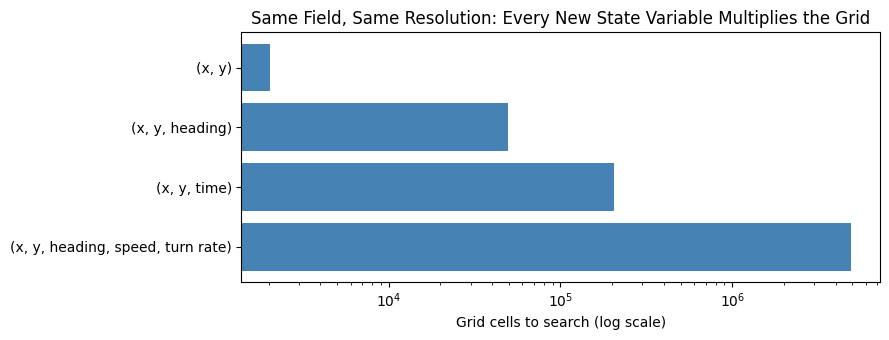

In [5]:
# how many grid cells a search-based planner has to be ready to visit, as state dimensions are added
axis_cells = {
    "x": int(FIELD_LENGTH / CELL_SIZE),       # 0.25 m cells
    "y": int(FIELD_WIDTH / CELL_SIZE),
    "heading": 24,                            # 15 degree bins
    "time": 100,                              # a 10 s horizon at 0.1 s steps
    "speed": 10,                              # 10 speed bins
    "turn rate": 10,                          # 10 turn-rate bins
}
state_spaces = {
    "(x, y)": ["x", "y"],
    "(x, y, heading)": ["x", "y", "heading"],
    "(x, y, time)": ["x", "y", "time"],
    "(x, y, heading, speed, turn rate)": ["x", "y", "heading", "speed", "turn rate"],
}

labels, counts = [], []
for label, axes in state_spaces.items():
    count = int(np.prod([axis_cells[a] for a in axes]))
    labels.append(label)
    counts.append(count)
    print(f"{label:<36} {count:>12,} cells")

plt.figure(figsize=(9, 3.5))
plt.barh(labels[::-1], counts[::-1], color="steelblue")
plt.xscale("log")
plt.xlabel("Grid cells to search (log scale)")
plt.title("Same Field, Same Resolution: Every New State Variable Multiplies the Grid")
plt.tight_layout()
plt.show()

The 2D grid is about two thousand cells. Add heading and it's fifty thousand. Add time and it's two hundred thousand. Add speed and turn rate for a full kinodynamic state and it's nearly five million cells, and that's with deliberately coarse bins. Every one of those cells also has to consider several possible moves. 

This is the **curse of dimensionality**: the work a grid search does is tied to how finely you slice the space, and the slicing multiplies with every dimension.

A sampling-based planner helps break up this problem. **Rapidly-Exploring Random Tree (RRT)** grows a tree outward from the start, and each iteration does the same four things:

1. Sample a random state (with a small bias toward the goal).
2. Find the nearest node already in the tree.
3. Extend from that node a short distance toward the sample (known as **steer**).
4. Check that the new piece of path is collision-free. If so, add it to the tree.

Repeat until a node lands close enough to the goal. The tree only ever stores states it actually reached, so there's no grid and no resolution to turn up. Notice also that steps 1, 2, and 4 are the same for every problem. Almost all of the problem-specific physics lives in steer (and in what "collision-free" means). So we can write the loop once, as a function that takes those pieces as arguments, and reuse it for every problem in this section.

In [6]:
def rrt(start, sample_fn, distance_fn, extend_fn, goal_fn, max_iters, rng):
    """ A problem-agnostic RRT. All the problem-specific physics lives in the four callbacks:
      sample_fn(rng)                 -> a random state
      distance_fn(states, sample)    -> distance from every tree state to the sample (np.inf = can't reach)
      extend_fn(from_state, sample)  -> (new_state, segment_points), or None if the move is invalid
      goal_fn(state)                 -> True once a state is close enough to the goal
    Returns (nodes, parents, segments, goal_index), where goal_index is None if no path was found. """
    nodes = [start]
    parents = [-1]
    segments = [None]         # segments[i] = the points swept out going from parents[i] to nodes[i]
    for _ in range(max_iters):
        sample = sample_fn(rng)
        nearest = int(np.argmin(distance_fn(np.array(nodes), sample)))
        extended = extend_fn(nodes[nearest], sample)
        if extended is None:
            continue
        new_state, segment = extended
        nodes.append(new_state)
        parents.append(nearest)
        segments.append(segment)
        if goal_fn(new_state):
            return nodes, parents, segments, len(nodes) - 1
    return nodes, parents, segments, None

def trace_back(parents, index):
    """ Walk parent pointers from a node back to the root. Returns node indices, root first. """
    chain = [index]
    while parents[chain[-1]] != -1:
        chain.append(parents[chain[-1]])
    return chain[::-1]

### Problem A: Planning Around Robots That Are Moving

The A\* path from the earlier section routed around where the two tracked robots were at the moment we planned. In a real match they don't stand still (unless they break down, but we won't count on that happening). Let's give them the velocities `05`'s tracker would report, and test that A\* plan.

We plan it once from a snapshot, drive it at full speed, and check it against where the robots actually are at each moment.

In [7]:
# the same kind of tracked robots as section 1, but now with the velocities 05's tracker would report
moving_robots = [
    {"start": np.array([7.0, 8.0]),  "velocity": np.array([0.0, -1.5])},   # sweeping down across the field
    {"start": np.array([11.0, 0.0]), "velocity": np.array([0.0, 0.8])},    # sweeping up across the field
]
KEEP_OUT = 0.45 + SAFETY_MARGIN            # same inflated footprint as the occupancy grid
EGO_MAX_SPEED = 2.0                         # m/s
DT = 0.5                                    # s of motion per tree edge
T_MAX = 15.0                                # planning horizon, s

def robots_at(t):
    return np.array([r["start"] + r["velocity"] * t for r in moving_robots])

def in_field(xy):
    return 0 <= xy[0] <= FIELD_LENGTH and 0 <= xy[1] <= FIELD_WIDTH

def spacetime_free(p0, t0, p1, t1, n_checks=6):
    """ Is a straight move from (p0, t0) to (p1, t1) clear of every robot, at every moment along the way? """
    for frac in np.linspace(0, 1, n_checks):
        xy = p0 + frac * (p1 - p0)
        t = t0 + frac * (t1 - t0)
        if not in_field(xy):
            return False
        if np.min(np.linalg.norm(robots_at(t) - xy, axis=1)) <= KEEP_OUT:
            return False
    return True

ego_start = np.array([1.0, 4.0])
ego_goal = np.array([15.0, 4.0])

# naive baseline: plan once with A* on a snapshot of where the robots are *right now*, then drive it at full speed
snapshot_grid = np.zeros((grid_h, grid_w))
for pos in robots_at(0.0):
    d = np.sqrt((xx - pos[0]) ** 2 + (yy - pos[1]) ** 2)
    snapshot_grid[d <= KEEP_OUT] = 1
snapshot_path = a_star(snapshot_grid,
                       (int(ego_start[1] / CELL_SIZE), int(ego_start[0] / CELL_SIZE)),
                       (int(ego_goal[1] / CELL_SIZE), int(ego_goal[0] / CELL_SIZE)))
naive_xy = np.array([[(c + 0.5) * CELL_SIZE, (r + 0.5) * CELL_SIZE] for r, c in snapshot_path])
naive_arc = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(naive_xy, axis=0), axis=1))])
naive_t = naive_arc / EGO_MAX_SPEED

first_hit = next((i for i in range(len(naive_xy))
                  if np.min(np.linalg.norm(robots_at(naive_t[i]) - naive_xy[i], axis=1)) <= KEEP_OUT), None)
print(f"Snapshot A* path: {len(naive_xy)} cells, {naive_t[-1]:.1f} s to drive at {EGO_MAX_SPEED} m/s")
print("Collision at t = " + (f"{naive_t[first_hit]:.1f} s" if first_hit is not None else "none"))

Snapshot A* path: 57 cells, 7.0 s to drive at 2.0 m/s
Collision at t = 2.6 s


The snapshot plan drives straight into a robot, because the route that was clear at `t = 0` isn't clear when the ego robot gets there. A path that avoids moving obstacles has to be a path through space and time. It matters both where the robot is and when it is there! 

So the state becomes `(x, y, t)`, and the four RRT pieces change like this:

1. Sample a random point on the field and a random moment in time.
2. Nearest only nodes that come before the sampled time are candidates, since a robot can't travel backward in time.
3. Steer by advancing time by one step, and moving toward the sample by at most `max speed x step`. Or we don't move at all, if the sample is where we already are. That last case is what lets the planner wait for a robot to pass.
4. Test points along the move against every robot's position at that point's time, not at `t = 0`.

Nothing else about the loop changes.

RRT found a path using 68 tree nodes
Arrives at t = 11.0 s (snapshot A* path would have taken 7.0 s, if it survived)


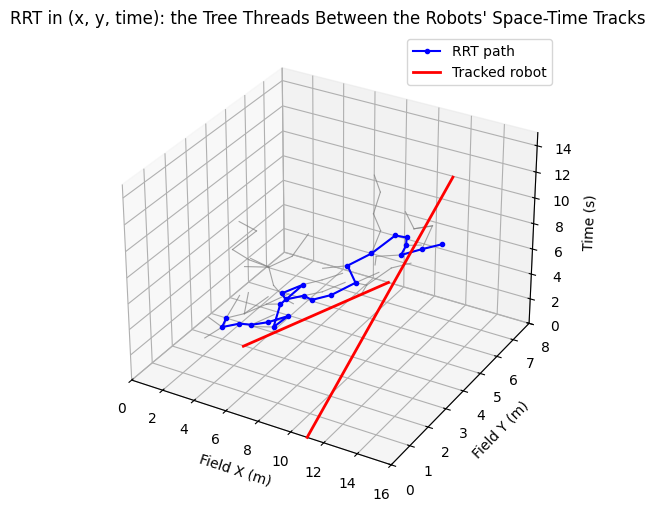

In [8]:
def sample_spacetime(rng):
    xy = np.array([ego_goal[0], ego_goal[1]]) if rng.random() < 0.1 else \
         rng.uniform([0, 0], [FIELD_LENGTH, FIELD_WIDTH])        # 10% goal bias
    return np.array([xy[0], xy[1], rng.uniform(0, T_MAX)])

def distance_spacetime(states, sample):
    dxy = np.linalg.norm(states[:, :2] - sample[:2], axis=1)
    dt = sample[2] - states[:, 2]
    return np.where(dt > 0, np.hypot(dxy, dt), np.inf)      # a node can't reach a sample that is in its past

def extend_spacetime(from_state, sample):
    new_t = from_state[2] + DT
    if new_t > T_MAX:
        return None
    to_sample = sample[:2] - from_state[:2]
    reach = EGO_MAX_SPEED * DT                              # how far we can get in one edge
    step = to_sample if np.linalg.norm(to_sample) <= reach else to_sample / np.linalg.norm(to_sample) * reach
    new_xy = from_state[:2] + step                          # step may be ~0: that's "wait here"
    if not spacetime_free(from_state[:2], from_state[2], new_xy, new_t):
        return None
    return np.array([new_xy[0], new_xy[1], new_t]), np.array([new_xy])

def reached_goal_spacetime(state):
    return np.linalg.norm(state[:2] - ego_goal) < 0.5

st_start = np.array([ego_start[0], ego_start[1], 0.0])
rng = np.random.default_rng(0)
st_nodes, st_parents, _, st_goal_idx = rrt(st_start, sample_spacetime, distance_spacetime,
                                           extend_spacetime, reached_goal_spacetime, 5000, rng)
assert st_goal_idx is not None, "RRT found no path in 5000 iterations - try a larger T_MAX or slower robots"
print(f"RRT found a path using {len(st_nodes)} tree nodes")

st_chain = trace_back(st_parents, st_goal_idx)
rrt_path = np.array([st_nodes[i] for i in st_chain])          # columns: x, y, t
print(f"Arrives at t = {rrt_path[-1, 2]:.1f} s (snapshot A* path would have taken {naive_t[-1]:.1f} s, if it survived)")

# the same tree, drawn in all three dimensions
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection="3d")
for i in range(1, len(st_nodes)):
    a, b = st_nodes[st_parents[i]], st_nodes[i]
    ax.plot([a[0], b[0]], [a[1], b[1]], [a[2], b[2]], color="gray", linewidth=0.8, alpha=0.7)
ax.plot(rrt_path[:, 0], rrt_path[:, 1], rrt_path[:, 2], "o-", color="blue", markersize=3, label="RRT path")
ts = np.linspace(0, T_MAX, 150)
for k, r in enumerate(moving_robots):
    track = np.array([r["start"] + r["velocity"] * t for t in ts])
    on_field = (track[:, 1] >= 0) & (track[:, 1] <= FIELD_WIDTH)        # stop drawing once it leaves the field
    ax.plot(track[on_field, 0], track[on_field, 1], ts[on_field], color="red", linewidth=2,
            label="Tracked robot" if k == 0 else None)
ax.set_xlabel("Field X (m)")
ax.set_ylabel("Field Y (m)")
ax.set_zlabel("Time (s)")
ax.set_xlim(0, FIELD_LENGTH)
ax.set_ylim(0, FIELD_WIDTH)
ax.set_zlim(0, T_MAX)
ax.set_title("RRT in (x, y, time): the Tree Threads Between the Robots' Space-Time Tracks")
ax.legend()
plt.show()

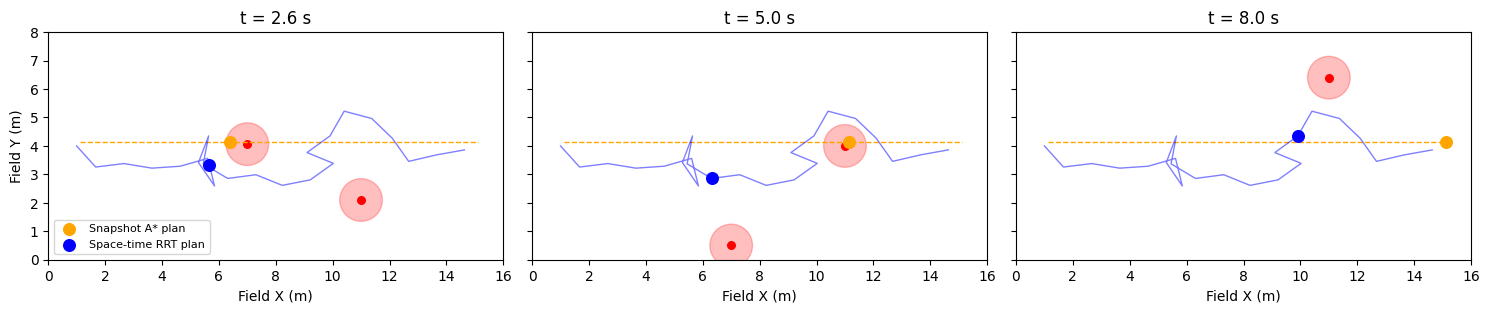

Closest the RRT plan ever gets to a robot's center: 1.39 m (keep-out radius 0.75 m)


In [9]:
# the same two plans at three moments in time: the snapshot plan's first collision, its second, and later

rrt_xy_at = lambda t: np.array([np.interp(t, rrt_path[:, 2], rrt_path[:, 0]),
                                np.interp(t, rrt_path[:, 2], rrt_path[:, 1])])
naive_xy_at = lambda t: np.array([np.interp(t, naive_t, naive_xy[:, 0]),
                                  np.interp(t, naive_t, naive_xy[:, 1])])

moments = [naive_t[first_hit] if first_hit is not None else 2.0, 5.0, 8.0]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, t in zip(axes, moments):
    for pos in robots_at(t):
        ax.add_patch(plt.Circle(pos, KEEP_OUT, color="red", alpha=0.25))
        ax.scatter(*pos, color="red", s=30)
    ax.plot(naive_xy[:, 0], naive_xy[:, 1], "--", color="orange", linewidth=1)
    ax.scatter(*naive_xy_at(t), color="orange", s=70, zorder=5, label="Snapshot A* plan")
    ax.plot(rrt_path[:, 0], rrt_path[:, 1], "-", color="blue", linewidth=1, alpha=0.5)
    ax.scatter(*rrt_xy_at(t), color="blue", s=70, zorder=5, label="Space-time RRT plan")
    ax.set_xlim(0, FIELD_LENGTH)
    ax.set_ylim(0, FIELD_WIDTH)
    ax.set_aspect("equal")
    ax.set_title(f"t = {t:.1f} s")
    ax.set_xlabel("Field X (m)")
axes[0].set_ylabel("Field Y (m)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

# verify the RRT plan with the same moment-by-moment check the baseline failed
dense_t = np.arange(0, rrt_path[-1, 2], 0.05)
worst_clearance = min(np.min(np.linalg.norm(robots_at(t) - rrt_xy_at(t), axis=1)) for t in dense_t)
print(f"Closest the RRT plan ever gets to a robot's center: {worst_clearance:.2f} m (keep-out radius {KEEP_OUT:.2f} m)")

In the first two frames the orange snapshot plan is sitting inside a robot's red keep-out circle, first with the robot sweeping down, then the one sweeping up. The blue RRT plan holds back near the start while the first robot sweeps through, then crosses the robots' lanes after they've moved on. It arrives later, but it never gets close to a robot.

You might fairly ask whether you need RRT for this at all, since time-expanded A\* can solve the same problem on a `(x, y, t)` grid. It can, so let's try it at several resolutions and do a comparison.

In [10]:
import time

def a_star_spacetime(start_xy, goal_xy, cell=0.5):
    """ A* over a grid of (x, y, time) cells. Each move advances time by exactly DT and can
    travel at most EGO_MAX_SPEED * DT, or stay put (wait). Returns (path_xyt or None, cells expanded). """
    nx, ny, nt = int(FIELD_LENGTH / cell), int(FIELD_WIDTH / cell), int(T_MAX / DT) + 1
    cx, cy = (np.arange(nx) + 0.5) * cell, (np.arange(ny) + 0.5) * cell
    gx, gy = np.meshgrid(cx, cy)                                  # shape (ny, nx)
    occupied = np.zeros((nt, ny, nx), dtype=bool)                 # the whole space-time obstacle volume
    for k in range(nt):
        for pos in robots_at(k * DT):
            occupied[k] |= np.hypot(gx - pos[0], gy - pos[1]) <= KEEP_OUT

    reach = int(EGO_MAX_SPEED * DT / cell)                        # in cells
    moves = [(dx, dy) for dx in range(-reach, reach + 1) for dy in range(-reach, reach + 1)
             if np.hypot(dx, dy) * cell <= EGO_MAX_SPEED * DT + 1e-9]
    start = (int(start_xy[0] / cell), int(start_xy[1] / cell), 0)
    goal_cell = (int(goal_xy[0] / cell), int(goal_xy[1] / cell))
    heuristic = lambda c: np.hypot(c[0] - goal_cell[0], c[1] - goal_cell[1]) * cell

    open_set = [(heuristic(start), 0.0, start)]
    came_from, best_cost, expanded = {}, {start: 0.0}, 0
    while open_set:
        _, g, current = heapq.heappop(open_set)
        if g > best_cost[current]:
            continue                                              # stale queue entry
        expanded += 1
        if np.hypot(current[0] - goal_cell[0], current[1] - goal_cell[1]) * cell < 0.5:
            path = [current]
            while path[-1] in came_from:
                path.append(came_from[path[-1]])
            return np.array([[(i + 0.5) * cell, (j + 0.5) * cell, k * DT] for i, j, k in path[::-1]]), expanded
        if current[2] + 1 >= nt:
            continue
        for dx, dy in moves:
            ni, nj, nk = current[0] + dx, current[1] + dy, current[2] + 1
            if not (0 <= ni < nx and 0 <= nj < ny) or occupied[nk, nj, ni]:
                continue
            new_cost = g + np.hypot(dx, dy) * cell + 0.01         # tiny time penalty so waiting isn't free
            if new_cost < best_cost.get((ni, nj, nk), np.inf):
                best_cost[(ni, nj, nk)] = new_cost
                came_from[(ni, nj, nk)] = current
                heapq.heappush(open_set, (new_cost + heuristic((ni, nj)), new_cost, (ni, nj, nk)))
    return None, expanded

def path_length(xy):
    return float(np.sum(np.linalg.norm(np.diff(xy, axis=0), axis=1)))

print(f"{'planner':<28}{'nodes touched':>15}{'time (ms)':>12}{'path (m)':>11}{'arrives (s)':>13}")
for cell in [1.0, 0.5, 0.25, 0.125]:
    t0 = time.perf_counter()
    path, expanded = a_star_spacetime(ego_start, ego_goal, cell=cell)
    ms = (time.perf_counter() - t0) * 1000
    if path is None:
        print(f"{f'A* with {cell} m cells':<28}{expanded:>15,}{ms:>12.0f}{'no path':>11}")
        continue
    print(f"{f'A* with {cell} m cells':<28}{expanded:>15,}{ms:>12.0f}{path_length(path[:, :2]):>11.1f}{path[-1, 2]:>13.1f}")

# RRT doesn't have a resolution to turn up, so instead run it across several random seeds
runs = []
for seed in range(10):
    t0 = time.perf_counter()
    nodes, parents, _, goal_idx = rrt(st_start, sample_spacetime, distance_spacetime, extend_spacetime,
                                      reached_goal_spacetime, 5000, np.random.default_rng(seed))
    ms = (time.perf_counter() - t0) * 1000
    path = np.array([nodes[i] for i in trace_back(parents, goal_idx)])
    runs.append((len(nodes), ms, path_length(path[:, :2]), path[-1, 2]))
med = np.median(np.array(runs), axis=0)
print(f"{'RRT (median of 10 seeds)':<28}{med[0]:>15,.0f}{med[1]:>12.0f}{med[2]:>11.1f}{med[3]:>13.1f}")

planner                       nodes touched   time (ms)   path (m)  arrives (s)
A* with 1.0 m cells                     150           1       14.0          9.0
A* with 0.5 m cells                     273           5       14.0          8.5


A* with 0.25 m cells                  1,218          50       13.8          8.5


A* with 0.125 m cells                 5,754         841       13.6          8.0
RRT (median of 10 seeds)                 90           5       20.8         10.8


A few important takeaways. 

A\* is genuinely good at this problem. With a strong heuristic it touches few nodes, and it returns noticeably shorter paths than RRT, because it's optimal on its grid and RRT is not, and at coarse resolution it's just as fast. In 3D at a sensible resolution, a grid search is a perfectly good answer.

However, look at how A\*'s cost grows. Every time the cells get finer, the work multiplies (several times over per halving) while RRT has no resolution to turn up, and its cost stays flat.

So the real rule is not "RRT beats A\*". It's that grid search is the right tool while the state is small enough to grid, and sampling is what's left when it isn't.

### Problem B: A Robot That Can't Turn in Place

Time was one extra dimension. Heading, or the orientation of the front of the robot, presents a new dimension, with a physical limit on how fast it can change. Real drivetrains have limits like this, and a 2D planner has no idea they exist.

We'll model the simplest version of it. A robot that drives forward at constant speed and can turn at a bounded rate (a "Dubins car"), with state `(x, y, heading)`, and the tightest circle it can drive has a radius of speed divided by max turn rate (1 meter here). 

Only one RRT piece changes. Steer no longer draws a straight line toward the sample. It forward-simulates a short arc for each turn rate the robot is allowed, and keeps whichever arc ends closest to the sample. Every edge in the tree is therefore something the robot can really drive.

The robot starts facing away from its goal, which is exactly the situation a 2D planner can't see.

A* path: its first move needs a 180 degree heading change before the robot has moved at all
         (this robot's tightest turn has a 1.0 m radius, so it can't do that in place)

RRT found a path using 76 tree nodes
RRT path: sharpest turn rate used is 1.00 rad/s (limit 1.0 rad/s)


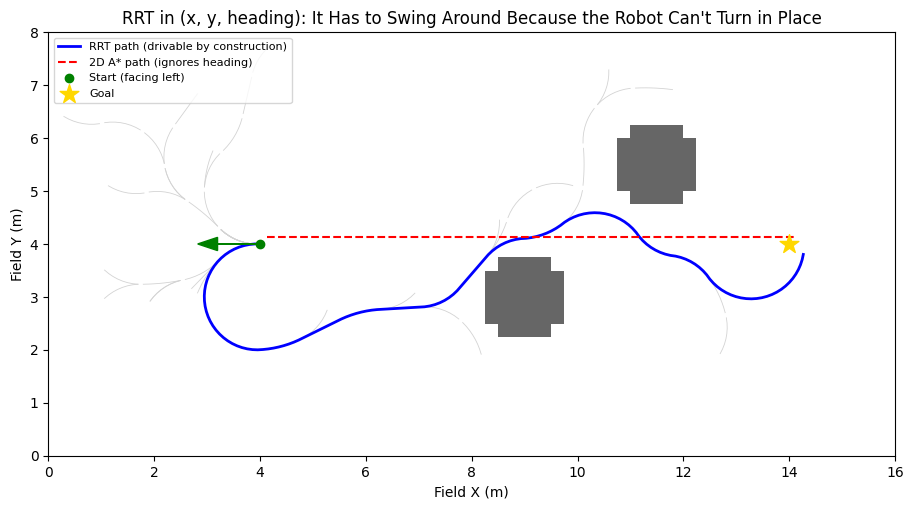

In [11]:
CRUISE_SPEED = 1.0                      # m/s, constant forward speed (no spinning in place, no reversing)
OMEGA_MAX = 1.0                         # rad/s -> tightest turn has radius CRUISE_SPEED / OMEGA_MAX = 1.0 m
ARC_TIME = 0.8                          # s of driving per tree edge
TURN_CHOICES = np.linspace(-OMEGA_MAX, OMEGA_MAX, 9)

wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi

def static_free(xy):
    """ Is a point inside the field and out of every occupied cell of the section-1 occupancy grid? """
    if not (0 <= xy[0] < FIELD_LENGTH and 0 <= xy[1] < FIELD_WIDTH):
        return False
    return grid[int(xy[1] / CELL_SIZE), int(xy[0] / CELL_SIZE)] == 0

def drive_arc(state, omega, n_steps=8):
    """ Forward-simulate the robot for ARC_TIME at a constant turn rate. Returns the points visited. """
    x, y, theta = state
    dt = ARC_TIME / n_steps
    points = []
    for _ in range(n_steps):
        x += CRUISE_SPEED * np.cos(theta) * dt
        y += CRUISE_SPEED * np.sin(theta) * dt
        theta = wrap(theta + omega * dt)
        points.append([x, y, theta])
    return np.array(points)

def sample_pose(rng):
    xy = kin_goal[:2] if rng.random() < 0.1 else rng.uniform([0, 0], [FIELD_LENGTH, FIELD_WIDTH])
    return np.array([xy[0], xy[1], 0.0])

def distance_pose(states, sample):
    dxy = sample[:2] - states[:, :2]
    bearing = np.arctan2(dxy[:, 1], dxy[:, 0])
    return np.hypot(dxy[:, 0], dxy[:, 1]) + 0.5 * np.abs(wrap(bearing - states[:, 2]))   # prefer nodes already facing the sample

def extend_pose(from_state, sample):
    # try every turn rate we're allowed, keep whichever arc ends closest to the sample
    arcs = [drive_arc(from_state, w) for w in TURN_CHOICES]
    best = min(arcs, key=lambda arc: np.linalg.norm(arc[-1, :2] - sample[:2]))
    if not all(static_free(p[:2]) for p in best):
        return None
    return best[-1], best

def reached_goal_pose(state):
    return np.linalg.norm(state[:2] - kin_goal[:2]) < 0.6

kin_start = np.array([4.0, 4.0, np.pi])      # facing *away* from the goal
kin_goal = np.array([14.0, 4.0, 0.0])

# the 2D baseline: A* on the same grid, which knows nothing about heading
flat_path = a_star(grid, (int(kin_start[1] / CELL_SIZE), int(kin_start[0] / CELL_SIZE)),
                   (int(kin_goal[1] / CELL_SIZE), int(kin_goal[0] / CELL_SIZE)))
flat_xy = np.array([[(c + 0.5) * CELL_SIZE, (r + 0.5) * CELL_SIZE] for r, c in flat_path])
first_move = flat_xy[1] - flat_xy[0]
first_heading_error = np.degrees(abs(wrap(np.arctan2(first_move[1], first_move[0]) - kin_start[2])))

print(f"A* path: its first move needs a {first_heading_error:.0f} degree heading change before the robot has moved at all")
print(f"         (this robot's tightest turn has a {CRUISE_SPEED / OMEGA_MAX:.1f} m radius, so it can't do that in place)")

rng = np.random.default_rng(0)
k_nodes, k_parents, k_segments, k_goal_idx = rrt(kin_start, sample_pose, distance_pose, extend_pose,
                                                 reached_goal_pose, 6000, rng)
assert k_goal_idx is not None, "RRT found no path in 6000 iterations - try a looser OMEGA_MAX or a different start"
print(f"\nRRT found a path using {len(k_nodes)} tree nodes")

k_chain = trace_back(k_parents, k_goal_idx)
k_path = np.array([k_nodes[i] for i in k_chain])
turn_rates = np.abs(wrap(np.diff(k_path[:, 2]))) / ARC_TIME
print(f"RRT path: sharpest turn rate used is {turn_rates.max():.2f} rad/s (limit {OMEGA_MAX:.1f} rad/s)")

plt.figure(figsize=(11, 5.5))
plt.imshow(grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
for i in range(1, len(k_nodes)):
    seg = k_segments[i]
    plt.plot(seg[:, 0], seg[:, 1], color="lightgray", linewidth=0.6)
drivable = np.concatenate([k_segments[i] for i in k_chain[1:]])
plt.plot(drivable[:, 0], drivable[:, 1], "-", color="blue", linewidth=2, label="RRT path (drivable by construction)")
plt.plot(flat_xy[:, 0], flat_xy[:, 1], "--", color="red", linewidth=1.5, label="2D A* path (ignores heading)")
plt.arrow(kin_start[0], kin_start[1], 0.8 * np.cos(kin_start[2]), 0.8 * np.sin(kin_start[2]),
          head_width=0.25, color="green", zorder=6)
plt.scatter(*kin_start[:2], color="green", zorder=6, label="Start (facing left)")
plt.scatter(*kin_goal[:2], color="gold", marker="*", s=200, zorder=6, label="Goal")
plt.xlabel("Field X (m)")
plt.ylabel("Field Y (m)")
plt.title("RRT in (x, y, heading): It Has to Swing Around Because the Robot Can't Turn in Place")
plt.legend(loc="upper left", fontsize=8)
plt.show()

The 2D A\* path is the red dashed line, and it's fine as geometry, since it is a straight shot between the two obstacles. But its first move requires the robot to be facing the opposite way from where it actually starts, and the robot can't turn in place. The RRT path (blue) is the one that works because it swings around in a loop with a radius the robot can really drive, lines up, and then threads between the two obstacles. The faint gray arcs are the rest of the tree, which makes it easy to see what `steer` did differently; every edge is a curve, because every edge had to be drivable. The check that follows the plot confirms it, as the sharpest turn anywhere on the path equals the robot's limit and never exceeds it.

### Hybrid A\*: The Search-Based Answer

This isn't the only answer. **Hybrid A\*** adds heading to the search but keeps the state continuous, and it's a standard tool for autonomous-vehicle parking and low-speed maneuvering. Like A\*, it always expands the lowest-cost node next, where cost is what we've spent so far plus a heuristic guess at what's left. Unlike A\*, a node's successors aren't neighboring grid cells. They're the same drivable arcs `steer` used above, one for each turn rate the robot is allowed.

The grid only comes back in one place, which is deciding whether we've already been here. Each node gets binned by position and heading, and a new node is only kept if it's cheaper than whatever reached that bin before. That stops the search from exploding, while the states themselves stay continuous and every edge stays drivable.

For the heuristic we reuse the 2D idea. Run Dijkstra's algorithm outward from the goal across the occupancy grid, so every cell knows the length of the shortest obstacle-avoiding path from there to the goal (ignoring heading). It's the cheapest heuristic that already knows about the obstacles.

                nodes touched   time (ms)  edges in path   path (m)  max turn rate
Hybrid A*                 134          16             17       13.6         1.00 /s
RRT                        76           9             19       15.2         1.00 /s


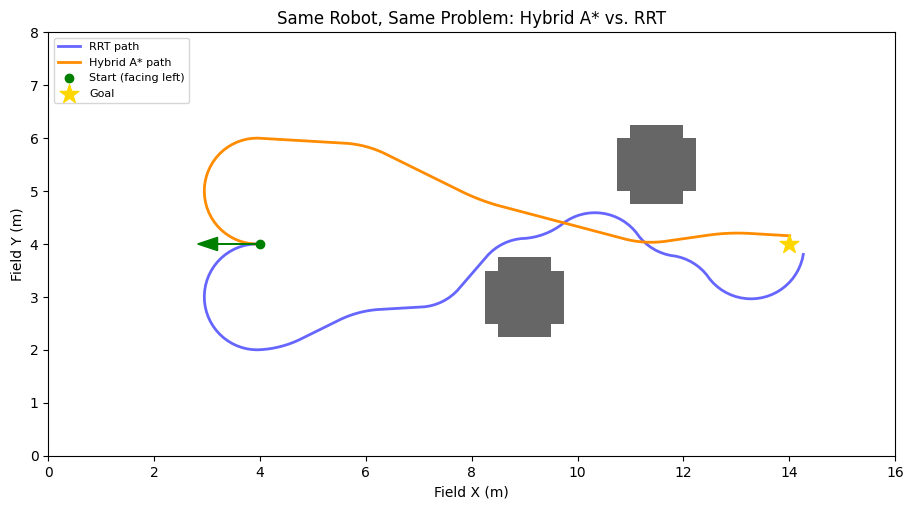

In [12]:
def grid_distance_to_goal(occupancy, goal_xy):
    """ Dijkstra outward from the goal over the occupancy grid. dist[row, col] is the length of the shortest
    obstacle-avoiding path from that cell to the goal, ignoring heading. Used as the search heuristic below. """
    dist = np.full(occupancy.shape, np.inf)
    goal_cell = (int(goal_xy[1] / CELL_SIZE), int(goal_xy[0] / CELL_SIZE))
    dist[goal_cell] = 0.0
    queue = [(0.0, goal_cell)]
    while queue:
        d, (r, c) = heapq.heappop(queue)
        if d > dist[r, c]:
            continue
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < occupancy.shape[0] and 0 <= nc < occupancy.shape[1] and occupancy[nr, nc] == 0:
                nd = d + np.hypot(dr, dc) * CELL_SIZE
                if nd < dist[nr, nc]:
                    dist[nr, nc] = nd
                    heapq.heappush(queue, (nd, (nr, nc)))
    return dist

HEADING_BINS = 24                          # 15 degree bins, as in the chart at the top of this section

def hybrid_a_star(start, goal_xy, dist_to_goal, goal_tol=0.6, max_expansions=20000):
    """ A* over (x, y, heading) where each successor is a drivable arc instead of a neighboring cell.
    Cells are only used to decide whether we've *already been here* - the states themselves stay continuous.
    Returns (states, parents, arcs, goal_index, expansions); goal_index is None if no path was found. """
    key = lambda s: (int(s[0] / CELL_SIZE), int(s[1] / CELL_SIZE), int((s[2] % (2 * np.pi)) / (2 * np.pi / HEADING_BINS)))
    h = lambda s: dist_to_goal[int(s[1] / CELL_SIZE), int(s[0] / CELL_SIZE)]
    states, parents, arcs = [np.asarray(start, dtype=float)], [-1], [None]
    best_cost = {key(states[0]): 0.0}
    queue = [(h(states[0]), 0.0, 0)]
    expansions = 0
    while queue and expansions < max_expansions:
        _, g, i = heapq.heappop(queue)
        state = states[i]
        if g > best_cost[key(state)] + 1e-9:
            continue                                       # a cheaper way into this cell was found since
        expansions += 1
        if np.linalg.norm(state[:2] - goal_xy) < goal_tol:
            return states, parents, arcs, i, expansions
        for omega in TURN_CHOICES:
            arc = drive_arc(state, omega)
            if not all(static_free(p[:2]) for p in arc):
                continue
            new_g = g + CRUISE_SPEED * ARC_TIME + 0.1 * abs(omega) / OMEGA_MAX     # small penalty for turning
            k = key(arc[-1])
            if new_g < best_cost.get(k, np.inf):
                best_cost[k] = new_g
                states.append(arc[-1]); parents.append(i); arcs.append(arc)
                heapq.heappush(queue, (new_g + h(arc[-1]), new_g, len(states) - 1))
    return states, parents, arcs, None, expansions

dist_map = grid_distance_to_goal(grid, kin_goal[:2])
t0 = time.perf_counter()
h_states, h_parents, h_arcs, h_goal_idx, h_expanded = hybrid_a_star(kin_start, kin_goal[:2], dist_map)
h_ms = (time.perf_counter() - t0) * 1000

# time RRT on the same problem, with the same seed as before, so it rebuilds the identical tree
t0 = time.perf_counter()
rrt(kin_start, sample_pose, distance_pose, extend_pose, reached_goal_pose, 6000, np.random.default_rng(0))
rrt_ms = (time.perf_counter() - t0) * 1000
assert h_goal_idx is not None, "Hybrid A* found no path"

h_chain = trace_back(h_parents, h_goal_idx)
h_path = np.concatenate([h_arcs[i] for i in h_chain[1:]])
h_turn_rates = np.abs(wrap(np.diff(np.array([h_states[i] for i in h_chain])[:, 2]))) / ARC_TIME

print(f"{'':<14}{'nodes touched':>15}{'time (ms)':>12}{'edges in path':>15}{'path (m)':>11}{'max turn rate':>15}")
print(f"{'Hybrid A*':<14}{h_expanded:>15,}{h_ms:>12.0f}{len(h_chain) - 1:>15}{(len(h_chain) - 1) * CRUISE_SPEED * ARC_TIME:>11.1f}{h_turn_rates.max():>13.2f} /s")
print(f"{'RRT':<14}{len(k_nodes):>15,}{rrt_ms:>12.0f}{len(k_chain) - 1:>15}{(len(k_chain) - 1) * CRUISE_SPEED * ARC_TIME:>11.1f}{turn_rates.max():>13.2f} /s")

plt.figure(figsize=(11, 5.5))
plt.imshow(grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
plt.plot(drivable[:, 0], drivable[:, 1], "-", color="blue", linewidth=2, alpha=0.6, label="RRT path")
plt.plot(h_path[:, 0], h_path[:, 1], "-", color="darkorange", linewidth=2, label="Hybrid A* path")
plt.arrow(kin_start[0], kin_start[1], 0.8 * np.cos(kin_start[2]), 0.8 * np.sin(kin_start[2]),
          head_width=0.25, color="green", zorder=6)
plt.scatter(*kin_start[:2], color="green", zorder=6, label="Start (facing left)")
plt.scatter(*kin_goal[:2], color="gold", marker="*", s=200, zorder=6, label="Goal")
plt.xlabel("Field X (m)")
plt.ylabel("Field Y (m)")
plt.title("Same Robot, Same Problem: Hybrid A* vs. RRT")
plt.legend(loc="upper left", fontsize=8)
plt.show()

Hybrid A\* expanded a few more nodes than the RRT tree contains, and takes a bit longer to run than RRT here, but the path it returns is shorter and smoother, and it's deterministic. Run it twice and you get the same answer, which RRT can't promise. At three dimensions that's hard to beat.

It does come with compromises. The bins mean the result is only approximately optimal, and the number of bins still multiplies with every dimension you add. That's why the sampling side of the field keeps going as the state gets bigger, and it's why we're not done with RRT yet.

### RRT\*: Making the Path Good

Plain RRT returns a path, not a good one. Once it finds the goal it has no reason to improve, and its first path tends to be jagged and long. **RRT\*** adds two steps after each new node is added:

- **Choose parent**: instead of attaching to the nearest node, attach to whichever nearby node gives the cheapest route from the start.
- **Rewire**: offer the new node to its neighbors as a better parent. If routing a neighbor through it is cheaper, reconnect the neighbor and push the saving down to all of its descendants.

The path gets shorter the longer you let it run, and converges toward the optimum. That "keep improving until you run out of time" behavior is called **anytime**, and it's a big part of why RRT\* is used on real systems.

Rewiring needs one thing the kinodynamic problems above don't give us for free, which is an exact way to connect any two states. For straight lines in 2D that's trivial; for a robot with turn limits it's a hard sub-problem of its own (a two-point boundary-value problem). So we'll show RRT\* in the simple 2D setting first, with a wall across the field and a 1.5 m gap in it, and come back to the turn-limited version once we've solved that sub-problem.

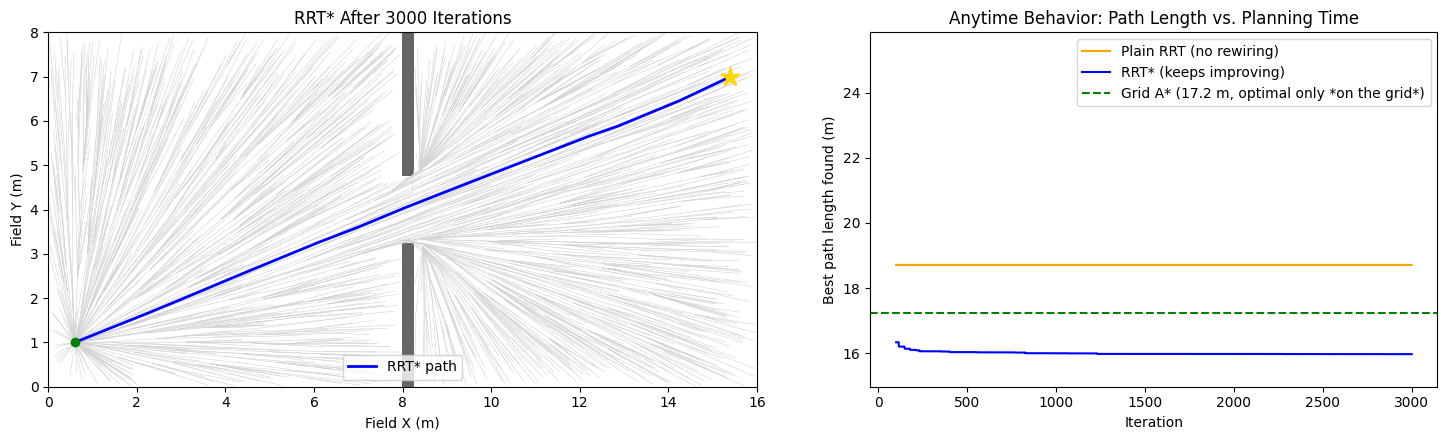

Plain RRT final path:  18.7 m
RRT* final path:       16.0 m   (grid A*: 17.2 m)


In [13]:
def segment_free(occupancy, a, b):
    """ Straight-line collision check against an occupancy grid, sampled twice per cell. """
    n = max(2, int(np.linalg.norm(b - a) / (CELL_SIZE / 2)) + 1)
    pts = a + np.linspace(0, 1, n)[:, None] * (b - a)
    if (pts < 0).any() or (pts[:, 0] >= FIELD_LENGTH).any() or (pts[:, 1] >= FIELD_WIDTH).any():
        return False
    return not occupancy[(pts[:, 1] / CELL_SIZE).astype(int), (pts[:, 0] / CELL_SIZE).astype(int)].any()

def rrt_star(occupancy, start, goal, iters, rng, step=0.6, radius=1.8, goal_tol=0.5, optimize=True, stop_at_first=False):
    """ 2D RRT. With optimize=True it becomes RRT*: each new node picks the cheapest nearby parent, then offers
    itself as a cheaper parent to its neighbors ("rewiring"). Returns (nodes, parents, costs, goal-reaching node indices, best-cost history). """
    nodes, parents, costs, children = [start], [-1], [0.0], {0: set()}
    history = []
    goal_nodes = []
    for _ in range(iters):
        sample = goal if rng.random() < 0.05 else rng.uniform([0, 0], [FIELD_LENGTH, FIELD_WIDTH])
        pts = np.array(nodes)
        nearest = int(np.argmin(np.linalg.norm(pts - sample, axis=1)))
        direction = sample - nodes[nearest]
        dist = np.linalg.norm(direction)
        if dist < 1e-9:
            history.append(history[-1] if history else np.inf)
            continue
        new = nodes[nearest] + direction / dist * min(step, dist)
        if not segment_free(occupancy, nodes[nearest], new):
            history.append(history[-1] if history else np.inf)
            continue

        parent, cost = nearest, costs[nearest] + np.linalg.norm(new - nodes[nearest])
        near = np.where(np.linalg.norm(pts - new, axis=1) <= radius)[0] if optimize else []
        for j in near:                                      # choose-parent: cheapest *collision-free* way in
            c = costs[j] + np.linalg.norm(new - nodes[j])
            if c < cost and segment_free(occupancy, nodes[j], new):
                parent, cost = int(j), c
        idx = len(nodes)
        nodes.append(new); parents.append(parent); costs.append(cost)
        children[idx] = set(); children[parent].add(idx)

        for j in near:                                      # rewire: can the new node shorten anyone's route?
            c = cost + np.linalg.norm(nodes[j] - new)
            if c < costs[j] - 1e-9 and j != parent and segment_free(occupancy, new, nodes[j]):
                children[parents[j]].discard(int(j))
                parents[j] = idx; children[idx].add(int(j))
                delta, stack = c - costs[j], [int(j)]
                while stack:                                # push the saving down to every descendant
                    k = stack.pop()
                    costs[k] += delta
                    stack.extend(children[k])

        if np.linalg.norm(new - goal) <= goal_tol and segment_free(occupancy, new, goal):
            goal_nodes.append(idx)
            if stop_at_first:
                history.append(costs[idx] + np.linalg.norm(goal - new))
                break
        history.append(min((costs[g] + np.linalg.norm(goal - nodes[g]) for g in goal_nodes), default=np.inf))
    return nodes, parents, costs, goal_nodes, history

# a wall across the field with a 1.5 m gap in it (6 cells), and the sealed wall's start/goal from earlier
open_gap_grid = wall_grid.copy()
open_gap_grid[grid_h // 2 - 3: grid_h // 2 + 3, wall_col] = 0
rs_start = np.array([0.6, 1.0])             # start and goal deliberately *not* lined up with the gap
rs_goal = np.array([15.4, 7.0])

optimal_cells = a_star(open_gap_grid, (int(rs_start[1] / CELL_SIZE), int(rs_start[0] / CELL_SIZE)),
                       (int(rs_goal[1] / CELL_SIZE), int(rs_goal[0] / CELL_SIZE)))
optimal_len = sum(np.hypot(a[0] - b[0], a[1] - b[1]) for a, b in zip(optimal_cells, optimal_cells[1:])) * CELL_SIZE

N_ITERS = 3000
plain = rrt_star(open_gap_grid, rs_start, rs_goal, N_ITERS, np.random.default_rng(1), optimize=False)
star = rrt_star(open_gap_grid, rs_start, rs_goal, N_ITERS, np.random.default_rng(1), optimize=True)

fig, (ax_map, ax_cost) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
nodes, parents, costs, goal_nodes, _ = star
best = min(goal_nodes, key=lambda g: costs[g] + np.linalg.norm(rs_goal - nodes[g]))
ax_map.imshow(open_gap_grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
for i in range(1, len(nodes)):
    ax_map.plot(*zip(nodes[parents[i]], nodes[i]), color="lightgray", linewidth=0.4)
chain = trace_back(parents, best)
route = np.vstack([np.array([nodes[i] for i in chain]), rs_goal])
ax_map.plot(route[:, 0], route[:, 1], "-", color="blue", linewidth=2, label="RRT* path")
ax_map.scatter(*rs_start, color="green", zorder=5)
ax_map.scatter(*rs_goal, color="gold", marker="*", s=200, zorder=5)
ax_map.set_title(f"RRT* After {N_ITERS} Iterations")
ax_map.set_xlabel("Field X (m)")
ax_map.set_ylabel("Field Y (m)")
ax_map.legend()

ax_cost.plot(plain[4], color="orange", label="Plain RRT (no rewiring)")
ax_cost.plot(star[4], color="blue", label="RRT* (keeps improving)")
ax_cost.axhline(optimal_len, color="green", linestyle="--", label=f"Grid A* ({optimal_len:.1f} m, optimal only *on the grid*)")
ax_cost.set_ylim(min(optimal_len, star[4][-1]) - 1, optimal_len * 1.5)
ax_cost.set_xlabel("Iteration")
ax_cost.set_ylabel("Best path length found (m)")
ax_cost.set_title("Anytime Behavior: Path Length vs. Planning Time")
ax_cost.legend()
plt.tight_layout()
plt.show()

print(f"Plain RRT final path:  {plain[4][-1]:.1f} m")
print(f"RRT* final path:       {star[4][-1]:.1f} m   (grid A*: {optimal_len:.1f} m)")

Plain RRT (orange) finds a path early and then never improves, because it has no mechanism to. RRT\* (blue) keeps tightening the same tree for as long as it runs and settles near the best length it can reach. It can even end *below* the grid A\* line: that A\* result is optimal only among paths that move along the grid's eight directions, while RRT\* works in continuous space and isn't limited to those headings.

### Making RRT\* Work With a Turn Limit

RRT\*'s choose-parent and rewire steps both lean on the same question: what's the cheapest way to get from *this* state to *that* one? For straight lines in 2D, the answer is just the distance. For a robot that can't turn in place, it's a real **two-point boundary-value problem**: find the path that starts at one pose (position *and* heading), ends at another, and obeys the turn limit the whole way. Our `steer` function from earlier didn't solve this. It only tried to get closer to a sample. RRT\* needs a path that gets there exactly.

For this robot (constant speed, bounded turn rate, forward only), the problem has a clean exact solution. In 1957 Lester Dubins proved that the shortest path between any two poses is always made of three pieces, each one a left arc (L), a right arc (R), or a straight line (S). That leaves only six possible shapes: LSL, RSR, LSR, RSL, RLR, and LRL. For a given pair of poses we use geometry to find the length of every shape that exists, then keep the shortest. These are called **Dubins paths**.

In [14]:
MIN_RADIUS = CRUISE_SPEED / OMEGA_MAX         # the tightest circle this robot can drive: 1.0 m
two_pi = lambda a: a % (2 * np.pi)

def dubins_candidates(start, end, rho=MIN_RADIUS):
    """ Every Dubins path that exists between two poses (both (x, y, heading)) for a robot that only drives
    forward and turns no tighter than radius rho. There are six possible shapes, made of left arcs (L),
    right arcs (R), and straight lines (S). Returns {word: segment lengths in meters}. """
    dx, dy = end[0] - start[0], end[1] - start[1]
    d = np.hypot(dx, dy) / rho                                       # work in units of the turning radius
    bearing = np.arctan2(dy, dx)
    a, b = two_pi(start[2] - bearing), two_pi(end[2] - bearing)     # both headings, relative to the line between them
    sa, ca, sb, cb = np.sin(a), np.cos(a), np.sin(b), np.cos(b)
    c_ab = np.cos(a - b)

    candidates = {}
    p_sq = 2 + d**2 - 2 * c_ab + 2 * d * (sa - sb)                  # LSL
    if p_sq >= 0:
        t1 = np.arctan2(cb - ca, d + sa - sb)
        candidates["LSL"] = (two_pi(-a + t1), np.sqrt(p_sq), two_pi(b - t1))
    p_sq = 2 + d**2 - 2 * c_ab + 2 * d * (sb - sa)                  # RSR
    if p_sq >= 0:
        t1 = np.arctan2(ca - cb, d - sa + sb)
        candidates["RSR"] = (two_pi(a - t1), np.sqrt(p_sq), two_pi(-b + t1))
    p_sq = -2 + d**2 + 2 * c_ab + 2 * d * (sa + sb)                 # LSR
    if p_sq >= 0:
        p = np.sqrt(p_sq)
        t1 = np.arctan2(-ca - cb, d + sa + sb) - np.arctan2(-2.0, p)
        candidates["LSR"] = (two_pi(-a + t1), p, two_pi(-b + t1))
    p_sq = -2 + d**2 + 2 * c_ab - 2 * d * (sa + sb)                 # RSL
    if p_sq >= 0:
        p = np.sqrt(p_sq)
        t1 = np.arctan2(ca + cb, d - sa - sb) - np.arctan2(2.0, p)
        candidates["RSL"] = (two_pi(a - t1), p, two_pi(b - t1))
    t0 = (6 - d**2 + 2 * c_ab + 2 * d * (sa - sb)) / 8              # RLR
    if abs(t0) <= 1:
        p = two_pi(2 * np.pi - np.arccos(t0))
        t = two_pi(a - np.arctan2(ca - cb, d - sa + sb) + p / 2)
        candidates["RLR"] = (t, p, two_pi(a - b - t + p))
    t0 = (6 - d**2 + 2 * c_ab + 2 * d * (sb - sa)) / 8              # LRL
    if abs(t0) <= 1:
        p = two_pi(2 * np.pi - np.arccos(t0))
        t = two_pi(-a - np.arctan2(ca - cb, d + sa - sb) + p / 2)
        candidates["LRL"] = (t, p, two_pi(b - a - t + p))

    return {word: np.array(segs) * rho for word, segs in candidates.items()}

def dubins_shortest(start, end, rho=MIN_RADIUS):
    """ The shortest of the candidate paths. Dubins (1957) proved the optimum is always one of the six.
    Returns (length, word, segment lengths). """
    candidates = dubins_candidates(start, end, rho)
    word = min(candidates, key=lambda w: candidates[w].sum())
    return candidates[word].sum(), word, candidates[word]

def dubins_sample(start, word, lengths, rho=MIN_RADIUS, step=0.1, max_length=np.inf):
    """ Walk along a Dubins path and return its (x, y, heading) points, about `step` meters apart,
    stopping early if the path is longer than max_length. """
    x, y, theta = start
    points = [[x, y, theta]]
    remaining = max_length
    for kind, seg_len in zip(word, lengths):
        seg_len = min(seg_len, remaining)
        if seg_len <= 0:
            break
        remaining -= seg_len
        n = max(1, int(np.ceil(seg_len / step)))
        ds = seg_len / n
        for _ in range(n):
            if kind == "S":
                x, y = x + ds * np.cos(theta), y + ds * np.sin(theta)
            else:                                                    # a circular arc: left turns and right turns mirror each other
                sign = 1 if kind == "L" else -1
                new_theta = theta + sign * ds / rho
                x += sign * rho * (np.sin(new_theta) - np.sin(theta))
                y += sign * rho * (np.cos(theta) - np.cos(new_theta))
                theta = wrap(new_theta)
            points.append([x, y, theta])
    return np.array(points)

Here's one example of each of the six shapes, always starting from the same pose (green) and ending at a different one (gold).

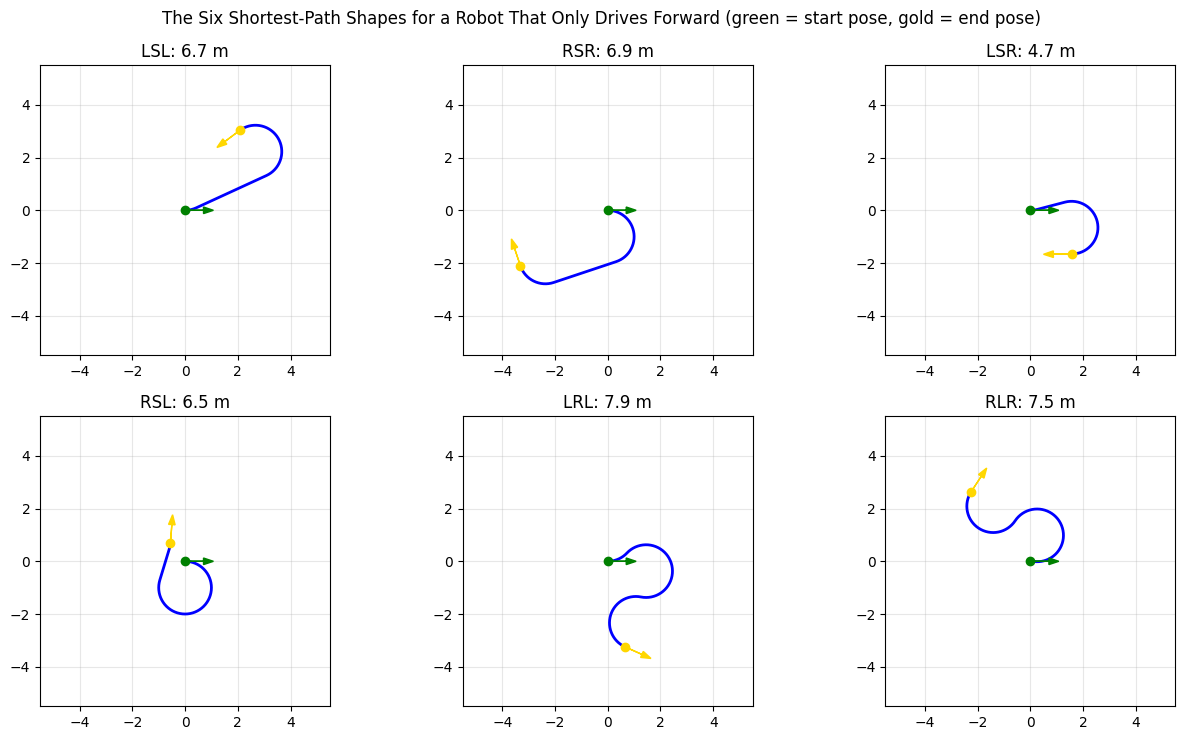

Worst miss over 500 random pose pairs, every candidate shape: 7.7e-13 (meters or radians)


In [15]:
# find one example of each of the six shapes, starting from the same pose each time
gallery_rng = np.random.default_rng(3)
gallery_start = np.array([0.0, 0.0, 0.0])
examples = {}
while len(examples) < 6:
    end = np.array([*gallery_rng.uniform(-4, 4, 2), gallery_rng.uniform(-np.pi, np.pi)])
    if np.linalg.norm(end[:2]) < 0.5:
        continue
    length, word, segs = dubins_shortest(gallery_start, end)
    examples.setdefault(word, (end, length, segs))

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, word in zip(axes.ravel(), ["LSL", "RSR", "LSR", "RSL", "LRL", "RLR"]):
    end, length, segs = examples[word]
    pts = dubins_sample(gallery_start, word, segs)
    ax.plot(pts[:, 0], pts[:, 1], "-", color="blue", linewidth=2)
    for pose, color in [(gallery_start, "green"), (end, "gold")]:
        ax.arrow(pose[0], pose[1], 0.7 * np.cos(pose[2]), 0.7 * np.sin(pose[2]), head_width=0.25, color=color, zorder=5)
        ax.scatter(*pose[:2], color=color, zorder=5)
    ax.set_title(f"{word}: {length:.1f} m")
    ax.set_aspect("equal")
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 5.5)
    ax.grid(alpha=0.3)
plt.suptitle("The Six Shortest-Path Shapes for a Robot That Only Drives Forward (green = start pose, gold = end pose)")
plt.tight_layout()
plt.show()

# trust, but verify: every candidate path should end exactly on its target pose
worst = 0.0
verify_rng = np.random.default_rng(0)
for _ in range(500):
    a = np.array([*verify_rng.uniform(0, 16, 2), verify_rng.uniform(-np.pi, np.pi)])
    b = np.array([*verify_rng.uniform(0, 16, 2), verify_rng.uniform(-np.pi, np.pi)])
    for word, segs in dubins_candidates(a, b).items():
        pts = dubins_sample(a, word, segs, step=0.05)
        worst = max(worst, np.linalg.norm(pts[-1, :2] - b[:2]), abs(wrap(pts[-1, 2] - b[2])))
print(f"Worst miss over 500 random pose pairs, every candidate shape: {worst:.1e} (meters or radians)")

The printout under the plot is a test, not decoration. RRT\* is going to trust these paths completely, so it's worth confirming that every candidate path, for 500 random pairs of poses, lands on its target pose to within about a trillionth of a meter. Since Dubins proved the best path is always one of the six, and each of the six lands exactly where it should, taking the shortest gives us the optimum.

Now we can run RRT\* on the turn-limited robot, using the same two steps as before but with Dubins paths in place of straight lines. We steer along the Dubins path toward a sample (but only part of the way), choose the parent with the cheapest exact connection, and rewire neighbors through the new node whenever that's cheaper. At every new node near the goal we also try to connect to the exact goal *pose*, so the final heading comes out right too. Here's the wall with a gap again, but with the robot starting out facing away from it.

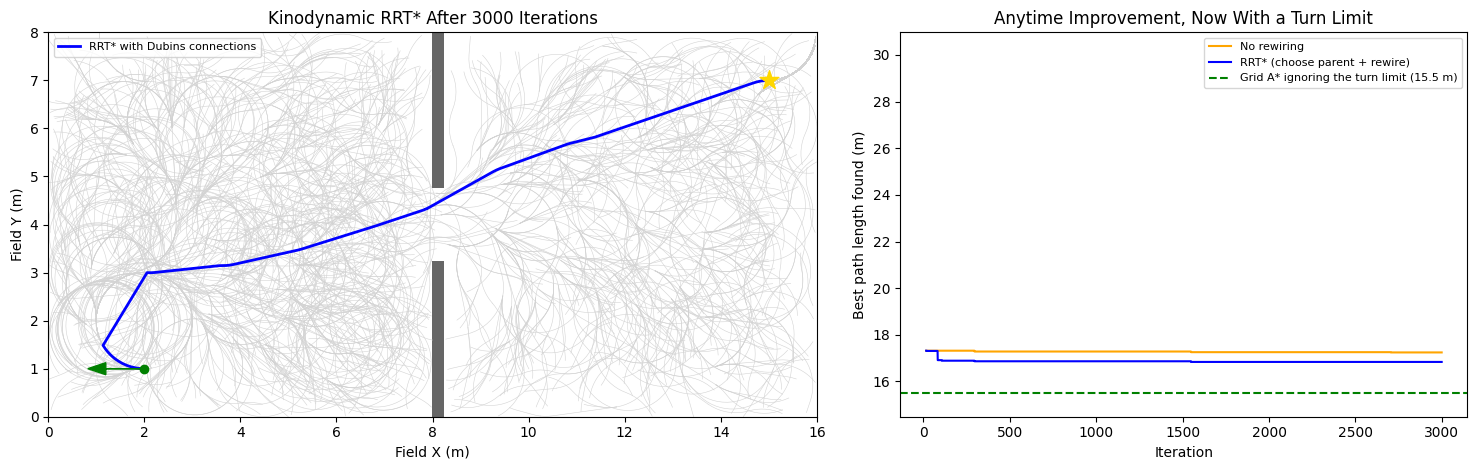

No rewiring: 17.2 m   |   RRT*: 16.8 m   (ran in 1.7 s)
Grid A* with no turn limit: 15.5 m, so the turn limit costs RRT* about 1.3 m of extra driving


In [16]:
def points_free(xy, occupancy):
    """ Are all of these points inside the field and out of every occupied cell? (vectorized static_free) """
    if (xy[:, 0] < 0).any() or (xy[:, 0] >= FIELD_LENGTH).any() or (xy[:, 1] < 0).any() or (xy[:, 1] >= FIELD_WIDTH).any():
        return False
    return not occupancy[(xy[:, 1] / CELL_SIZE).astype(int), (xy[:, 0] / CELL_SIZE).astype(int)].any()

def rrt_star_dubins(occupancy, start, goal, iters, rng, step=1.6, radius=2.5, optimize=True):
    """ RRT* for the turn-limited robot. Same loop as the 2D version, except every "connect these two states"
    is a Dubins path instead of a straight line. """
    states, parents, costs, edges, children = [start], [-1], [0.0], [None], {0: set()}
    goal_links = {}                    # node index -> length of the exact Dubins connection from it to the goal pose
    history = []
    for _ in range(iters):
        sample = goal if rng.random() < 0.1 else np.array([*rng.uniform([0, 0], [FIELD_LENGTH, FIELD_WIDTH]), rng.uniform(-np.pi, np.pi)])
        pts = np.array(states)
        nearest = int(np.argmin(distance_pose(pts, sample)))
        _, word, segs = dubins_shortest(states[nearest], sample)
        edge = dubins_sample(states[nearest], word, segs, max_length=step)      # steer: follow the Dubins path, but only so far
        if not points_free(edge[:, :2], occupancy):
            history.append(history[-1] if history else np.inf)
            continue
        new = edge[-1]
        step_len = min(step, segs.sum())
        parent, cost, parent_edge = nearest, costs[nearest] + step_len, edge

        near = [j for j in np.argsort(np.linalg.norm(pts[:, :2] - new[:2], axis=1))[:15]
                if np.linalg.norm(pts[j, :2] - new[:2]) <= radius] if optimize else []
        for j in near:                                  # choose parent: the cheapest *exact* connection into the new node
            if j == nearest:
                continue
            length, w, sg = dubins_shortest(states[j], new)
            if costs[j] + length < cost:
                e = dubins_sample(states[j], w, sg)
                if points_free(e[:, :2], occupancy):
                    parent, cost, parent_edge = int(j), costs[j] + length, e
        idx = len(states)
        states.append(new); parents.append(parent); costs.append(cost); edges.append(parent_edge)
        children[idx] = set(); children[parent].add(idx)

        for j in near:                                  # rewire: can the new node give a neighbor a cheaper route?
            if j == parent:
                continue
            length, w, sg = dubins_shortest(new, states[j])
            if cost + length < costs[j] - 1e-9:
                e = dubins_sample(new, w, sg)
                if points_free(e[:, :2], occupancy):
                    children[parents[j]].discard(int(j))
                    parents[j], edges[j] = idx, e
                    children[idx].add(int(j))
                    delta, stack = cost + length - costs[j], [int(j)]
                    while stack:
                        k = stack.pop()
                        costs[k] += delta
                        stack.extend(children[k])

        if np.linalg.norm(new[:2] - goal[:2]) < 4.0:    # try to finish: an exact connection to the goal *pose*
            length, w, sg = dubins_shortest(new, goal)
            if idx not in goal_links and points_free(dubins_sample(new, w, sg)[:, :2], occupancy):
                goal_links[idx] = length
        history.append(min((costs[g] + goal_links[g] for g in goal_links), default=np.inf))
    return states, parents, costs, edges, goal_links, history

# the wall-with-a-gap from the RRT* section, now with a robot that can't turn in place
kin_start2 = np.array([2.0, 1.0, np.pi])                     # facing away from the wall
kin_goal2 = np.array([15.0, 7.0, 0.0])
KIN_ITERS = 3000
t0 = time.perf_counter()
ks_star = rrt_star_dubins(open_gap_grid, kin_start2, kin_goal2, KIN_ITERS, np.random.default_rng(2), optimize=True)
star_secs = time.perf_counter() - t0
ks_plain = rrt_star_dubins(open_gap_grid, kin_start2, kin_goal2, KIN_ITERS, np.random.default_rng(2), optimize=False)

s_states, s_parents, s_costs, s_edges, s_links, s_hist = ks_star
best = min(s_links, key=lambda g: s_costs[g] + s_links[g])
chain = trace_back(s_parents, best)
_, w, sg = dubins_shortest(s_states[best], kin_goal2)
final_path = np.concatenate([s_edges[i][:, :2] for i in chain[1:]] + [dubins_sample(s_states[best], w, sg)[:, :2]])

# for reference: grid A* on the same wall, which ignores the turn limit entirely
ref_cells = a_star(open_gap_grid, (int(kin_start2[1] / CELL_SIZE), int(kin_start2[0] / CELL_SIZE)),
                   (int(kin_goal2[1] / CELL_SIZE), int(kin_goal2[0] / CELL_SIZE)))
ref_len = sum(np.hypot(a[0] - b[0], a[1] - b[1]) for a, b in zip(ref_cells, ref_cells[1:])) * CELL_SIZE

fig, (ax_map, ax_cost) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax_map.imshow(open_gap_grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
for i in range(1, len(s_states)):
    ax_map.plot(s_edges[i][:, 0], s_edges[i][:, 1], color="lightgray", linewidth=0.4)
ax_map.plot(final_path[:, 0], final_path[:, 1], "-", color="blue", linewidth=2, label="RRT* with Dubins connections")
ax_map.arrow(kin_start2[0], kin_start2[1], 0.8 * np.cos(kin_start2[2]), 0.8 * np.sin(kin_start2[2]), head_width=0.25, color="green", zorder=6)
ax_map.scatter(*kin_start2[:2], color="green", zorder=6)
ax_map.scatter(*kin_goal2[:2], color="gold", marker="*", s=200, zorder=6)
ax_map.set_title(f"Kinodynamic RRT* After {KIN_ITERS} Iterations")
ax_map.set_xlabel("Field X (m)")
ax_map.set_ylabel("Field Y (m)")
ax_map.legend(loc="upper left", fontsize=8)

ax_cost.plot(ks_plain[5], color="orange", label="No rewiring")
ax_cost.plot(s_hist, color="blue", label="RRT* (choose parent + rewire)")
ax_cost.axhline(ref_len, color="green", linestyle="--", label=f"Grid A* ignoring the turn limit ({ref_len:.1f} m)")
ax_cost.set_ylim(ref_len - 1, ref_len * 2)
ax_cost.set_xlabel("Iteration")
ax_cost.set_ylabel("Best path length found (m)")
ax_cost.set_title("Anytime Improvement, Now With a Turn Limit")
ax_cost.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"No rewiring: {ks_plain[5][-1]:.1f} m   |   RRT*: {s_hist[-1]:.1f} m   (ran in {star_secs:.1f} s)")
print(f"Grid A* with no turn limit: {ref_len:.1f} m, so the turn limit costs RRT* about {s_hist[-1] - ref_len:.1f} m of extra driving")

The path threads the gap and respects the turn limit everywhere. The orange curve is the same planner with rewiring turned off, and it ends up a little higher than the blue one, but be honest about how small that difference is. Steering along Dubins paths already builds a decent tree, so rewiring has less left to fix than it did in 2D. Across the handful of seeds I tried, the gain ranged from a tenth to a few tenths of a meter. The green line shows what the turn limit costs. Grid A\* ignores it and finds a shorter path, but one that this robot couldn't actually drive.

There are two limits to know about. First, this works because a closed-form answer exists for this particular robot. Add acceleration limits, or reversing, or a turn limit that depends on speed, and there's no formula. Kinodynamic RRT\* for those robots needs a numerical solver for the boundary-value problem at every single connection, which is far more expensive and still an active research area. Second, notice the gentle wobble in the path. Raw sampling-based paths are never perfectly clean, which is what we'll handle next.

### Cleaning Up the Path: Shortcutting and Smoothing

A raw RRT path wiggles because the tree grew toward random samples, and the path just records whichever way it happened to get there. Real systems almost always clean the path up before anything drives it. There are two standard steps.

**Shortcutting** picks two random points on the path, and if the straight link between them is allowed, deletes everything in between. Repeat a few hundred times. **Smoothing** then rounds off whatever corners are left. We'll use the simplest version, Chaikin corner cutting, which replaces each corner with two points a quarter and three quarters of the way along its adjacent segments. Every round halves the sharpness of every corner.

The important rule is that "allowed" has to mean exactly what it meant to the planner. A link has to be collision-free, and it has to respect every other constraint the planner did. In space-time, for example, a link is only legal if the robot can drive it within the time available at its speed limit. And the smoothing step has to re-check everything it produces, backing off if rounding a corner would clip an obstacle.

                                length (m)  vertices  biggest turn at a vertex
Plain RRT, raw                        17.3        31                      82 deg
Plain RRT, shortcut                   14.4         4                      35 deg
Plain RRT, shortcut + smooth          14.3        32                      14 deg
Space-time RRT, raw                   22.0        23                     170 deg
Space-time RRT, shortcut              13.6         2                       0 deg

Closest the shortcut space-time plan gets to a robot's center: 2.05 m (keep-out radius 0.75 m)


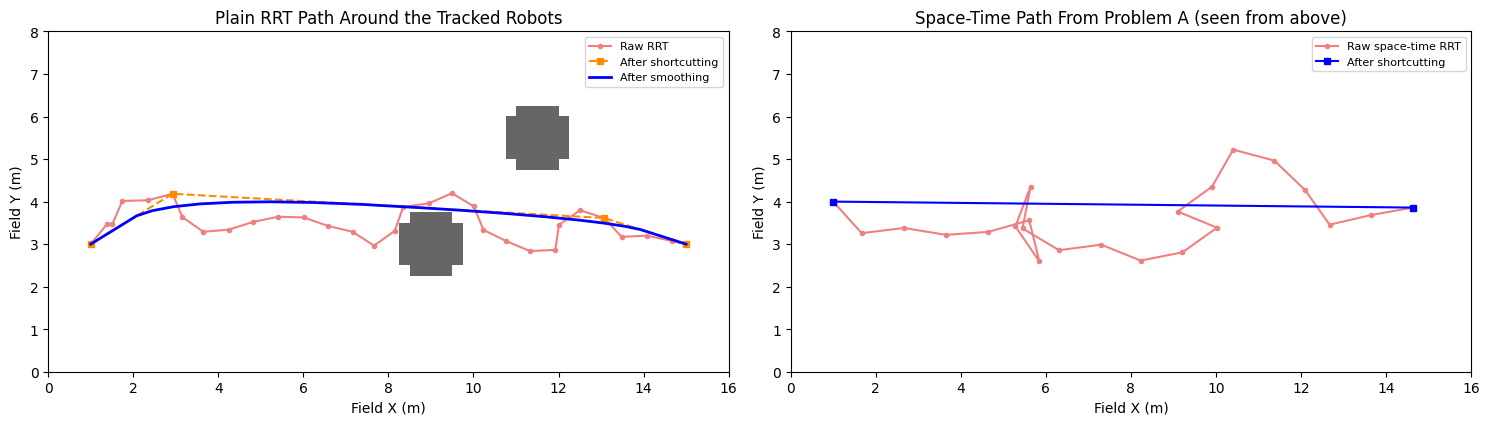

In [17]:
def shortcut(path, link_ok, rng, tries=400):
    """ Repeatedly pick two points on the path, and if the straight link between them is allowed, delete
    everything in between. `link_ok(a, b)` is whatever "allowed" means for this problem. """
    path = [p for p in path]
    for _ in range(tries):
        if len(path) < 3:
            break
        i, j = sorted(rng.choice(len(path), 2, replace=False))
        if j - i >= 2 and link_ok(path[i], path[j]):
            path = path[: i + 1] + path[j:]
    return np.array(path)

def chaikin(path, rounds):
    """ Corner cutting: replace every corner with two points, a quarter and three quarters of the way along
    each adjacent segment. Each round halves the sharpness of every corner. """
    for _ in range(rounds):
        a, b = path[:-1], path[1:]
        cut = np.empty((2 * len(a), 2))
        cut[0::2], cut[1::2] = 0.75 * a + 0.25 * b, 0.25 * a + 0.75 * b
        path = np.vstack([path[0], cut, path[-1]])
    return path

def smooth_safely(path, link_ok):
    """ Smooth as much as possible without any piece of the result becoming illegal. """
    for rounds in (3, 2, 1, 0):
        candidate = chaikin(path, rounds)
        if all(link_ok(a, b) for a, b in zip(candidate[:-1], candidate[1:])):
            return candidate
    return path

def path_stats(xy):
    """ (length in meters, number of vertices, largest heading change at any single vertex in degrees) """
    seg = np.diff(xy, axis=0)
    heading = np.arctan2(seg[:, 1], seg[:, 0])
    biggest_turn = np.degrees(np.abs(wrap(np.diff(heading))).max()) if len(seg) > 1 else 0.0
    return np.linalg.norm(seg, axis=1).sum(), len(xy), biggest_turn

# 1) a plain RRT path across the two-robot occupancy grid from the top of the notebook, on a line that runs
#    straight into one of the robots, so the cleaned-up path has to bend around it
bend_start, bend_goal = np.array([1.0, 3.0]), np.array([15.0, 3.0])
b_nodes, b_parents, b_costs, b_goal_nodes, _ = rrt_star(grid, bend_start, bend_goal, 1500, np.random.default_rng(3), optimize=False)
b_best = min(b_goal_nodes, key=lambda g: b_costs[g] + np.linalg.norm(bend_goal - b_nodes[g]))
raw_2d = np.vstack([np.array([b_nodes[i] for i in trace_back(b_parents, b_best)]), bend_goal])
wall_ok = lambda a, b: segment_free(grid, a, b)
short_2d = shortcut(list(raw_2d), wall_ok, np.random.default_rng(0))
smooth_2d = smooth_safely(short_2d, wall_ok)

# 2) the space-time path from Problem A. A link is legal if the robot can drive it in the time available AND it
#    stays clear of both moving robots the whole way - the same two rules the planner used.
def spacetime_link_ok(a, b):
    dt = b[2] - a[2]
    dist = np.linalg.norm(b[:2] - a[:2])
    return dt > 0 and dist <= EGO_MAX_SPEED * dt and spacetime_free(a[:2], a[2], b[:2], b[2], n_checks=max(6, int(dist / 0.1)))
raw_st = rrt_path
short_st = shortcut(list(raw_st), spacetime_link_ok, np.random.default_rng(0))

print(f"{'':<30}{'length (m)':>12}{'vertices':>10}{'biggest turn at a vertex':>26}")
for label, xy in [("Plain RRT, raw", raw_2d), ("Plain RRT, shortcut", short_2d), ("Plain RRT, shortcut + smooth", smooth_2d),
                  ("Space-time RRT, raw", raw_st[:, :2]), ("Space-time RRT, shortcut", short_st[:, :2])]:
    length, n, biggest = path_stats(xy)
    print(f"{label:<30}{length:>12.1f}{n:>10}{biggest:>24.0f} deg")

worst = min(np.min(np.linalg.norm(robots_at(t) - np.array([np.interp(t, short_st[:, 2], short_st[:, 0]),
                                                           np.interp(t, short_st[:, 2], short_st[:, 1])]), axis=1))
            for t in np.arange(0, short_st[-1, 2], 0.05))
print(f"\nClosest the shortcut space-time plan gets to a robot's center: {worst:.2f} m (keep-out radius {KEEP_OUT:.2f} m)")

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(15, 4.2))
ax_a.imshow(grid, origin="lower", extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Greys", alpha=0.6)
ax_a.plot(raw_2d[:, 0], raw_2d[:, 1], "o-", color="lightcoral", markersize=3, label="Raw RRT")
ax_a.plot(short_2d[:, 0], short_2d[:, 1], "s--", color="darkorange", markersize=4, label="After shortcutting")
ax_a.plot(smooth_2d[:, 0], smooth_2d[:, 1], "-", color="blue", linewidth=2, label="After smoothing")
ax_a.set_title("Plain RRT Path Around the Tracked Robots")
ax_a.legend(fontsize=8)
ax_b.plot(raw_st[:, 0], raw_st[:, 1], "o-", color="lightcoral", markersize=3, label="Raw space-time RRT")
ax_b.plot(short_st[:, 0], short_st[:, 1], "s-", color="blue", markersize=4, label="After shortcutting")
ax_b.set_xlim(0, FIELD_LENGTH)
ax_b.set_ylim(0, FIELD_WIDTH)
ax_b.set_title("Space-Time Path From Problem A (seen from above)")
ax_b.legend(fontsize=8)
for ax in (ax_a, ax_b):
    ax.set_xlabel("Field X (m)")
    ax.set_ylabel("Field Y (m)")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Shortcutting does most of the work. The plain-RRT path drops from 31 vertices to 4 and gets noticeably shorter, and smoothing then trades the one remaining corner for a gentle curve, which is the kind of path a follower like Pure Pursuit wants. The biggest heading change at any single vertex falls from 82 degrees to 14.

The space-time path is more surprising. Its shortcut collapsed to a *single straight line*: drive directly at the goal, just slowly enough to stay out of the way. All of the loitering and sideways wandering in the raw path was never needed. It was simply the first thing the random tree happened to find. The printout confirms the shortcut plan still stays well clear of both robots, and because the speed limit was part of what "allowed" meant, it's still something the robot can actually do.

One caveat is that this cleanup works on a polyline. It doesn't apply directly to the Dubins path above, since replacing a stretch of it with a straight line would break the turn limit. Post-processing has to respect the same constraints as the planner, and for a turn-limited robot the equivalent move is to try replacing a stretch with a single Dubins connection instead of a straight one.

### Where RRT Fails

The first failure is the narrow passage. RRT is only *probabilistically* complete, because given unlimited samples it will eventually find a path if one exists, but "eventually" can be very long when the only way through is a tiny target. A random sample almost never lands in a 0.25 m gap. Here's the same wall with a wide gap versus the one-cell gap from the sealed-wall check, with a fixed iteration budget across many random seeds.

In [18]:
# how often does each planner find *any* path in a fixed iteration budget, as the gap in the wall shrinks?
narrow_grid = wall_grid.copy()
narrow_grid[grid_h // 2, wall_col] = 0                      # the 1-cell (0.25 m) gap from section 2

BUDGET, SEEDS = 250, 20
print(f"Plain RRT, {BUDGET} iterations, {SEEDS} random seeds each:")
for label, occupancy in [("1.5 m gap ", open_gap_grid), ("0.25 m gap", narrow_grid)]:
    solved = 0
    for seed in range(SEEDS):
        _, _, _, goal_nodes, _ = rrt_star(occupancy, rs_start, rs_goal, BUDGET, np.random.default_rng(seed),
                                          optimize=False, stop_at_first=True)
        solved += bool(goal_nodes)
    print(f"  {label}: solved {solved}/{SEEDS}")
print("(for comparison, grid A* solves both gaps every time, as the sealed-wall check showed)")

Plain RRT, 250 iterations, 20 random seeds each:
  1.5 m gap : solved 18/20


  0.25 m gap: solved 10/20
(for comparison, grid A* solves both gaps every time, as the sealed-wall check showed)


The wide gap is solved almost every time. The narrow one fails often, and nothing in the planner's output tells you it came close, which leads to the second and worse problem: RRT can't tell you no path exists.

When A\* returned "no path" on the sealed wall, that was a guarantee. When RRT runs out of iterations it only knows it hasn't found one *yet*. For a robot that needs to decide whether to try a different plan, that's a real difference.

Two smaller issues come with the territory. Results vary by seed, so run the planner twice and you get two different paths, which makes tests and debugging harder. Fix the random seed when you need reproducibility. 

Raw paths are jagged, as the wiggles in the plans above show, which is why the cleanup step in the last section isn't optional.

### Which One to Reach For

| Situation | Reach for |
|---|---|
| Small state (a 2D position, maybe coarse 3D), and you need the shortest path or a guaranteed "no path" | Grid A\* |
| Obstacles don't move and the robot can turn freely | Grid A\* |
| Heading-limited robot, with a state small enough to bin (x, y, heading) | Hybrid A\* |
| State is high-dimensional, or too constrained to grid (heading limits, speed, time with many obstacles) | RRT, or RRT\* if path quality matters |
| You need an answer fast and a better one later | RRT\* (anytime) |
| Something is about to hit you *right now* | A reactive layer, like the potential field next |

A real planning stack usually layers these where a global planner (A\* or RRT) proposes a route, and a fast reactive layer handles whatever it didn't predict. That second layer is where we're headed next, and `10-full-autonomy-stack.ipynb` puts every piece together on one robot.

## A Simple Reactive Behavior You Can Build: Artificial Potential Fields

A\* and RRT both replan a whole path before moving. Sometimes a much simpler, purely reactive approach is enough. At every instant, treat the goal as attracting the robot and every nearby obstacle as repelling it, sum the resulting forces into a single direction, and just drive that way. This is an **artificial potential field**, and unlike A\*/RRT it needs no search and no tree, just one force calculation per tick. 

**Attractive force** pulls the robot toward the goal. It is a constant-strength pull while far away (so distant obstacles don't get overwhelmed by a runaway attraction), smoothly scaling down to zero right at the goal (so the robot decelerates into it instead of overshooting and oscillating around it forever).

**Repulsive force** pushes the robot away from each nearby obstacle, but only within some influence radius, so that an obstacle on the far side of the field shouldn't affect anything.

At every tick, sum every force acting on the robot into one vector, and step the robot a small distance in that direction.

Let's build it and drive a robot around a single obstacle that sits off to one side of the direct path.

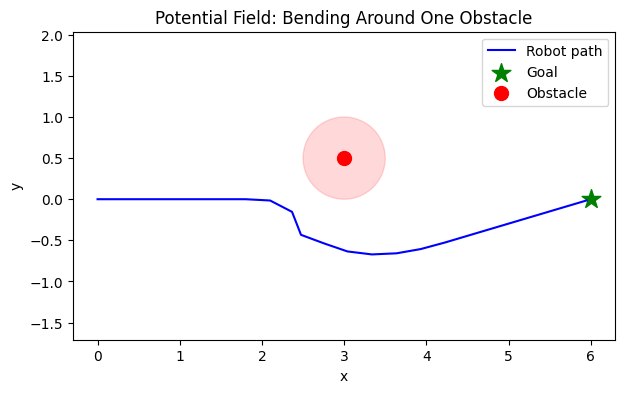

Reached goal in 22 steps, final distance to goal: 0.054
Closest approach to obstacle: 0.91


In [19]:
def potential_field_force(pos, goal, obstacles, k_att=1.0, k_rep=2.0, influence_radius=1.5,
                           max_speed=0.3, transition_distance=1.0):
    to_goal = goal - pos
    dist_to_goal = np.linalg.norm(to_goal)
    if dist_to_goal <= transition_distance:
        attractive = k_att * to_goal                                        # near the goal: shrink smoothly
    else:
        attractive = k_att * transition_distance * to_goal / dist_to_goal    # far away: constant strength

    repulsive = np.zeros(2)
    for obstacle in obstacles:
        away = pos - obstacle
        dist = np.linalg.norm(away)
        if dist < influence_radius and dist > 1e-6:
            repulsive += k_rep * (1.0 / dist - 1.0 / influence_radius) * (1.0 / dist ** 2) * (away / dist)

    force = attractive + repulsive
    speed = np.linalg.norm(force)
    return force * (max_speed / speed) if speed > max_speed else force

def drive(start, goal, obstacles, max_steps=300, tolerance=0.1, influence_radius=1.5):
    pos = start.copy()
    path = [pos.copy()]
    for _ in range(max_steps):
        if np.linalg.norm(goal - pos) < tolerance:
            break
        pos = pos + potential_field_force(pos, goal, obstacles, influence_radius=influence_radius)
        path.append(pos.copy())
    return np.array(path)

start = np.array([0.0, 0.0])
goal = np.array([6.0, 0.0])
obstacle = np.array([3.0, 0.5])

path = drive(start, goal, [obstacle])

plt.figure(figsize=(7, 4))
plt.plot(path[:, 0], path[:, 1], "-", color="blue", label="Robot path")
plt.scatter(*goal, color="green", marker="*", s=200, label="Goal")
plt.scatter(*obstacle, color="red", s=100, label="Obstacle")
plt.gca().add_patch(plt.Circle(obstacle, 0.5, color="red", alpha=0.15))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Potential Field: Bending Around One Obstacle")
plt.legend()
plt.axis("equal")
plt.show()

print(f"Reached goal in {len(path)} steps, final distance to goal: {np.linalg.norm(goal - path[-1]):.3f}")
print(f"Closest approach to obstacle: {np.min(np.linalg.norm(path - obstacle, axis=1)):.2f}")

The robot bends smoothly around the obstacle without ever having planned a path in advance. Every step is just "which direction is best right now." That reactivity is exactly what makes potential fields cheap and genuinely useful in a fast-moving FRC match. There's no replanning delay, no graph search, just a force calculation every tick.

It's also worth showing where this breaks.

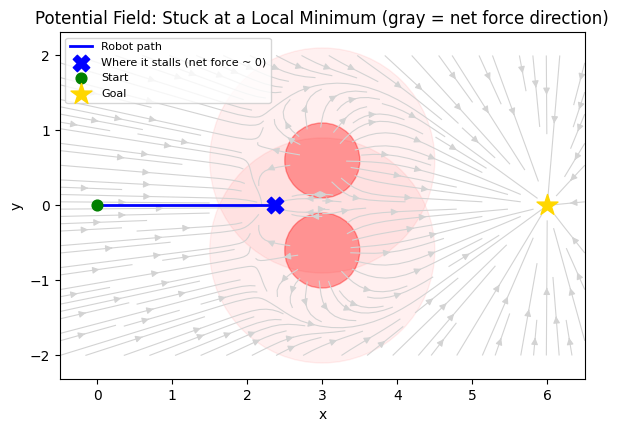

Steps taken: 301, reached goal: False
Final distance to goal: 3.633


In [20]:
# two obstacles placed to flank the direct path symmetrically
trap_obstacles = [np.array([3.0, 0.6]), np.array([3.0, -0.6])]
trap_path = drive(start, goal, trap_obstacles)

# the net force the robot would feel at every point on the field, to show *why* it stalls
gx, gy = np.meshgrid(np.linspace(-0.5, 6.5, 36), np.linspace(-2.0, 2.0, 21))
force_u, force_v = np.zeros_like(gx), np.zeros_like(gy)
for i in range(gx.shape[0]):
    for j in range(gx.shape[1]):
        p = np.array([gx[i, j], gy[i, j]])
        if min(np.linalg.norm(p - o) for o in trap_obstacles) < 0.5:
            force_u[i, j] = force_v[i, j] = np.nan               # inside an obstacle: nothing to draw
        else:
            force_u[i, j], force_v[i, j] = potential_field_force(p, goal, trap_obstacles)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.streamplot(gx, gy, np.nan_to_num(force_u), np.nan_to_num(force_v), color="lightgray", linewidth=0.8, density=1.4)
for obstacle in trap_obstacles:
    ax.add_patch(plt.Circle(obstacle, 1.5, color="red", alpha=0.06))              # influence radius
    ax.add_patch(plt.Circle(obstacle, 0.5, color="red", alpha=0.35))               # the obstacle itself
ax.plot(trap_path[:, 0], trap_path[:, 1], "-", color="blue", linewidth=2, label="Robot path")
ax.scatter(*trap_path[-1], marker="X", s=140, color="blue", zorder=6, label="Where it stalls (net force ~ 0)")
ax.scatter(*start, color="green", s=60, zorder=6, label="Start")
ax.scatter(*goal, color="gold", marker="*", s=250, zorder=6, label="Goal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Potential Field: Stuck at a Local Minimum (gray = net force direction)")
ax.set_aspect("equal")
ax.legend(loc="upper left", fontsize=8)
plt.show()

reached_goal = np.linalg.norm(goal - trap_path[-1]) < 0.1
print(f"Steps taken: {len(trap_path)}, reached goal: {reached_goal}")
print(f"Final distance to goal: {np.linalg.norm(goal - trap_path[-1]):.3f}")

With two obstacles placed symmetrically on either side of the straight-line path, their repulsive forces cancel out laterally, and the residual attractive pull exactly balances the combined repulsion. The robot gets stuck, permanently, well short of the goal. 

This is the textbook failure mode of potential fields, called a **local minimum**. It represents a point where every nearby force cancels out even though the goal is nowhere close. A\*/RRT don't have this problem, since they search or sample the whole space instead of only ever looking at the immediate local gradient, which is exactly the tradeoff. Potential fields are cheap and reactive but can get stuck; A\*/RRT are more expensive but complete (A\* is guaranteed to find a path if one exists, and RRT will eventually, given enough samples). A real system often runs both: a potential field (or similar reactive layer) for fast, cheap moment-to-moment avoidance, with a full replanner as the fallback for when the reactive layer stalls out.

## Speaking AV: Same Problems, Different Constraints

Everything in this primer has a direct analog in the self-driving car industry, so let us go over some of that vocabulary. 

The SAE (Society of Automotive Engineers) defines six levels of automation, from L0 (no automation) to L5 (full automation, anywhere, no human needed). FRC's teleop-with-vision-assist (`08`'s auto-align) is a genuine, if small-scale, instance of partial automation (roughly L2). The system handles a specific sub-task (steering to a target), but a human is still fully responsible for the vehicle overall and expected to take over instantly. FRC's autonomous period is closer to L4 (full self-driving, but only within a known, bounded, pre-mapped environment).

That known, bounded, and pre-mapped environment is known as an **Operational Design Domain (ODD).** No autonomous system (FRC or otherwise) is validated to work everywhere, under all conditions (although some are certainly getting closer). Its ODD is the specific set of conditions it's actually designed and tested for. A real self-driving car's ODD might be "this specific city, in daylight, in dry weather, under 45 mph." An FRC robot's autonomous code has an ODD too, even if no one calls it that. It is this year's specific field layout, this year's specific game piece, whatever lighting the venue happens to have. Stepping outside that ODD (e.g., a practice field with different lighting than competition, or a game piece that looks slightly different under the venue's lights) is exactly why `frc_resources/03_roboflow`'s iterate-on-real-footage loop matters. We need it so our ODD extends to any of the fields our robot drives on! 

Why does Waymo need radar and lidar, but we don't? `04` and `05` spent real effort solving problems that exist specifically *because* a camera only measures direction, not distance. We talked about monocular scale ambiguity, stereo triangulation, PnP, structure from motion, and more. A lidar sensor sidesteps essentially all of that by measuring range directly. It doesn't infer depth, it times a laser pulse's return. Radar adds something a camera can't get at all. It measures relative velocity directly via Doppler shift, rather than differentiating position estimates over time the way `05`'s velocity calculation had to. 

A real AV stacks camera + lidar + radar (+ ultrasonic for close range) mainly for redundancy, because a system with lives at stake can't simply stop working if one sensor is degraded by rain, glare, or darkness, the way an FRC robot safely can. FRC sticks to camera + wheel odometry not because the other sensors don't work, but because of real constraints AVs don't have. Things like weight, cost, and competition rules all change the way we have to operate.

For validation, a real AV company doesn't just ship a model that scored well on a held-out test set. It validates in simulation, watches a system run in shadow mode alongside a human driver without acting on anything, and tracks how often a safety driver has to disengage it. FRC teams don't have that budget or scale, but the underlying instinct is the same, and it's `frc_resources/03_roboflow`'s active-learning loop. We test on real conditions as early and often as possible, and let the failures (not a single validation-set score) tell you where to spend the next round of effort.

## Try It Yourself

Using the occupancy grid above, change one of the `tracked_robots` positions so it directly blocks more of `ego_path`, and re-run. Does the fraction of occupied path cells go up? Then add a third tracked robot somewhere off the path entirely, and confirm it doesn't change `blocked` at all.

In the A* example, try moving `goal_cell` to a spot directly inside one of the tracked robots' inflated footprints (e.g. `(12, 36)`, near the first robot). What does `a_star` return, and does that match what "no path exists" should mean here? Then try widening `SAFETY_MARGIN` back in the occupancy-grid cell to `0.8` and re-running the whole notebook from there. Does A*'s route change shape, and does it ever get forced to route between the two robots instead of around both?

In the potential field example, try increasing `influence_radius` for the single-obstacle case from `1.5` to `3.0`. Does the robot start bending away from the obstacle earlier? Does it still reach the goal cleanly?

Finally, in the local-minimum trap example, try `trap_obstacles = [np.array([2.5, 0.6]), np.array([3.5, -0.6])]` (staggered in *both* x and y, instead of the original pair that only differs in y) and re-run. Does the robot escape this time? Then try staggering only in y while keeping both obstacles at the same x (e.g. `[np.array([3.0, 0.7]), np.array([3.0, -0.5])]`). Does that alone break the trap? What does the difference between those two results tell you about why the original pair got the robot stuck in the first place: is it really about left-right symmetry, or about both obstacles sitting at the same distance along the direct path?

For the RRT sections: in the space-time example, change one of the `moving_robots` velocities so it moves faster, or add a third robot, and re-run. Does the planner still find a path, and does it wait longer? Compare the arrival times of the RRT plan and the time-expanded A* plan when you do. Which one adapts better?

In the kinematic example, raise `OMEGA_MAX` from `1.0` to `3.0` so the robot can turn much more tightly. Does the loop at the start shrink? Then set `kin_start`'s heading to `0.0` (facing the goal) and re-run. Does the RRT path look more like the 2D A* path?

Finally, in the failure-mode example, increase `BUDGET` from `250` to `3000`. Does the narrow gap get solved more often, and does it ever get solved every time? What does that tell you about the difference between "RRT can't solve this" and "RRT hasn't solved this yet". Is there any way for the planner itself to know which one it's in?

For the Hybrid A* example, change `kin_start` so the robot faces the goal (heading `0.0`) and re-run the cell. Does the path stay exactly the same from run to run, unlike RRT? Then try setting `HEADING_BINS` to `8`. Does it still find a path, and what changes: the path itself, or the amount of work to find it? What does that say about what the bins are really doing?

For the Dubins paths, call `dubins_shortest` on the same pair of poses with `rho=0.5`, then `rho=2.0`. How do the length and the winning shape change as the robot gets less agile? Then try a goal that's very close to the start but facing the opposite way. Which shapes win, and why?

For smoothing, change the `tries` argument of the `shortcut` call from `400` to `10`. How much of the cleanup survives? Then add a third robot to `moving_robots`, `{"start": np.array([8.0, 0.0]), "velocity": np.array([0.0, 0.7])}`, timed to cross the straight line right when the ego robot gets there, and re-run from the space-time cell down. Does the shortcut still collapse to a single segment? What stopped it?

## Resources

- Hart, P., Nilsson, N., & Raphael, B. (1968). "A Formal Basis for the Heuristic Determination of Minimum Cost Paths." *IEEE Transactions on Systems Science and Cybernetics*. The original A* paper - the exact algorithm implemented above (paper).
- [LaValle, S. *Planning Algorithms*](http://lavalle.pl/planning/) - the standard reference for A*, RRT, and the broader motion-planning field; free online.
- [AtsushiSakai/PythonRobotics](https://github.com/AtsushiSakai/PythonRobotics) - runnable, from-scratch Python implementations of RRT, potential fields, and most of the other algorithms named across this primer - a good next stop for the variants this notebook doesn't build, like Reeds-Shepp paths (Dubins paths for a robot that can also reverse) and Informed RRT\*.
- Karaman, S. & Frazzoli, E. (2011). "Sampling-based Algorithms for Optimal Motion Planning." *International Journal of Robotics Research*. The RRT\* paper, including the proof that it converges to the optimal path (paper).
- Dolgov, D., Thrun, S., Montemerlo, M., & Diebel, J. (2010). "Path Planning for Autonomous Vehicles in Unknown Semi-structured Environments." *International Journal of Robotics Research*. The Hybrid A\* paper, the search-based approach to heading-constrained planning mentioned above (paper).
- Dubins, L. E. (1957). "On Curves of Minimal Length with a Constraint on Average Curvature, and with Prescribed Initial and Terminal Positions and Tangents." *American Journal of Mathematics*. The original proof that the shortest path is always one of the six shapes used above (paper).
- Chaikin, G. (1974). "An Algorithm for High-Speed Curve Generation." *Computer Graphics and Image Processing*. The corner-cutting method used for smoothing above (paper).
- LaValle, S. (1998). "Rapidly-Exploring Random Trees: A New Tool for Path Planning." Technical Report, Iowa State University. The original RRT paper (paper).
- SAE International. *J3016: Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles.* The official source for the L0-L5 vocabulary used above (standard).